# Microproyecto 4: clasificación de sonidos de la naturaleza con AST

En este notebook se hace fine-tuning del Audio Spectrogram Transformer (AST) [1], una adaptación del transformer [2] que trabaja sobre espectrogramas, a partir del checkpoint `MIT/ast-finetuned-audioset-10-10-0.4593` [3]. Se usa el fold 1 de ESC-50 [4], descargado de Hugging Face, y se entrena durante 2 épocas.

Contenido:
1. Carga y exploración de los datos
2. Preprocesamiento: pipeline de audio a espectrogramas, Dataset y DataLoader
3. Creación del modelo
4. Entrenamiento del modelo preentrenado (2 épocas, 3 semillas)
5. Evaluación del modelo: precision, recall, F1, mejores y peores clases, matriz de confusión
6. Resultados cuantitativos: intervalos de confianza, comparación de configuraciones y figura de confusiones
7. Resultados cualitativos: análisis de errores, t-SNE y mapas de atención

## 1. Carga y exploración de los datos

In [4]:
# !pip install -q transformers datasets torch torchaudio scikit-learn matplotlib seaborn pandas numpy soundfile librosa accelerate

In [5]:
import random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torchaudio
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset, Audio
from transformers import ASTFeatureExtractor, ASTForAudioClassification
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
warnings.filterwarnings("ignore")

# tres semillas para reportar media ± desviación
SEEDS = [42, 43, 44]
SEED = SEEDS[0]
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE)

d:\Programas\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: cuda


In [6]:
# carga de datos
dataset     = load_dataset("confit/esc50-demo", "fold1", split="train")
val_dataset = load_dataset("confit/esc50-demo", "fold1", split="test")

print(dataset)
print(val_dataset)

Dataset({
    features: ['audio', 'sound', 'label'],
    num_rows: 1600
})
Dataset({
    features: ['audio', 'sound', 'label'],
    num_rows: 400
})


### 1.1 Exploración del dataset

In [7]:
print("Columnas:", dataset.column_names)
print("Features:", dataset.features)

# el nombre de la columna de etiquetas cambia según la versión del dataset
LABEL_COL = "category" if "category" in dataset.column_names else \
            ("label" if "label" in dataset.column_names else "target")
print("Columna de etiqueta usada:", LABEL_COL)

Columnas: ['audio', 'sound', 'label']
Features: {'audio': Audio(sampling_rate=44100, decode=True, num_channels=None, stream_index=None), 'sound': Value('string'), 'label': ClassLabel(names=['airplane', 'breathing', 'brushing_teeth', 'can_opening', 'car_horn', 'cat', 'chainsaw', 'chirping_birds', 'church_bells', 'clapping', 'clock_alarm', 'clock_tick', 'coughing', 'cow', 'crackling_fire', 'crickets', 'crow', 'crying_baby', 'dog', 'door_wood_creaks', 'door_wood_knock', 'drinking_sipping', 'engine', 'fireworks', 'footsteps', 'frog', 'glass_breaking', 'hand_saw', 'helicopter', 'hen', 'insects', 'keyboard_typing', 'laughing', 'mouse_click', 'pig', 'pouring_water', 'rain', 'rooster', 'sea_waves', 'sheep', 'siren', 'sneezing', 'snoring', 'thunderstorm', 'toilet_flush', 'train', 'vacuum_cleaner', 'washing_machine', 'water_drops', 'wind'])}
Columna de etiqueta usada: label


In [8]:
# diccionarios id <-> nombre de clase
if "target" in dataset.column_names and "category" in dataset.column_names:
    pairs = sorted(set(zip(dataset["target"], dataset["category"])) |
                   set(zip(val_dataset["target"], val_dataset["category"])))
    id2label = {int(t): str(c) for t, c in pairs}
else:
    names = sorted(set(map(str, dataset[LABEL_COL])) | set(map(str, val_dataset[LABEL_COL])))
    id2label = {i: n for i, n in enumerate(names)}
label2id = {v: k for k, v in id2label.items()}
NUM_LABELS = len(id2label)
CLASS_NAMES = [id2label[i] for i in range(NUM_LABELS)]
print(f"{NUM_LABELS} clases:", CLASS_NAMES)

def get_label_id(example):
    if "target" in example: return int(example["target"])
    return label2id[str(example[LABEL_COL])]

50 clases: ['0', '1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '3', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '4', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '5', '6', '7', '8', '9']


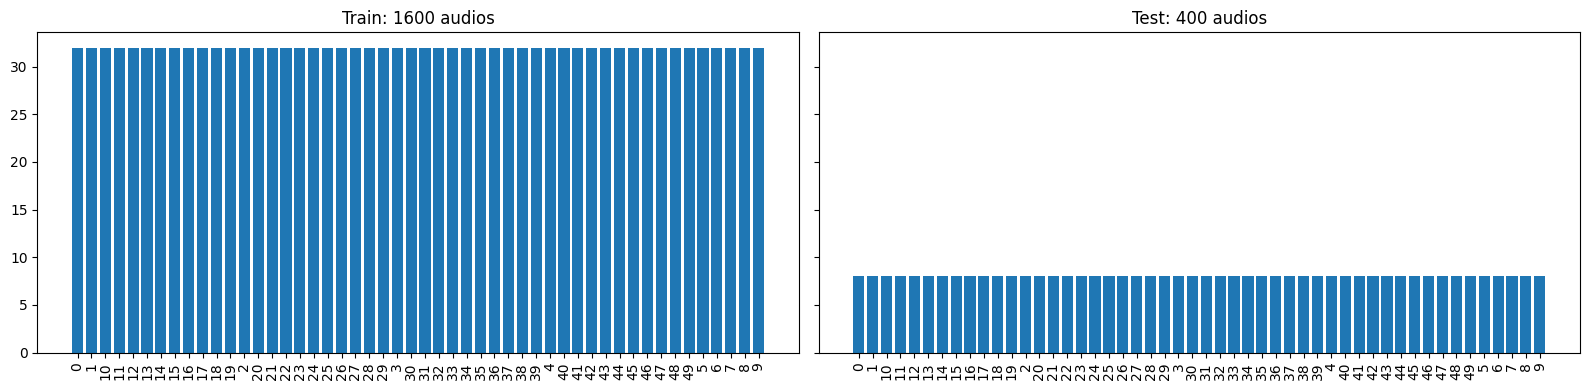

Ejemplo -> sampling_rate: 44100 | muestras: 220500 | duración (s): 5.00


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=True)
for ax, ds, name in zip(axes, [dataset, val_dataset], ["Train", "Test"]):
    ids = [get_label_id(ds[i]) for i in range(len(ds))]
    counts = pd.Series(ids).value_counts().sort_index()
    ax.bar([id2label[i] for i in counts.index], counts.values)
    ax.set_title(f"{name}: {len(ds)} audios"); ax.tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

def get_audio(a):
    """Devuelve la onda en mono y su frecuencia de muestreo (sirve para datasets 3.x y 4.x)."""
    if hasattr(a, "get_all_samples"):  # datasets 4.x devuelve un AudioDecoder
        smp = a.get_all_samples()
        return smp.data.float().mean(0), int(smp.sample_rate)
    arr = torch.as_tensor(np.asarray(a["array"]), dtype=torch.float32)
    if arr.ndim > 1:  # varios canales: promediar
        arr = arr.mean(dim=int(np.argmin(arr.shape)))
    return arr, int(a["sampling_rate"])

w0, sr0 = get_audio(dataset[0]["audio"])
print("Ejemplo -> sampling_rate:", sr0, "| muestras:", len(w0), "| duración (s): %.2f" % (len(w0) / sr0))

## 2. Preprocesamiento de los datos

### 2.1 Pipeline de audio a espectrogramas

El AST espera como entrada un espectrograma log-Mel de 1024 frames por 128 bandas, calculado a 16 kHz y normalizado con la media y la desviación estándar de AudioSet [5] (-4.27 y 4.57). La clase `SpectrogramPipeline` hace esa conversión en cinco pasos:

1. Paso a mono, promediando los canales si hay más de uno.
2. Remuestreo a 16 kHz, la frecuencia con la que se preentrenó el AST.
3. Espectrograma log-Mel con el fbank de Kaldi: ventana Hanning de 25 ms, salto de 10 ms y 128 bandas.
4. Relleno con ceros o recorte hasta 1024 frames (unos 10 s), de modo que todas las salidas miden 1024 x 128 sin importar la duración del audio.
5. Normalización (x - media) / (2 * std), aplicada después del relleno. Así la entrada queda con media cercana a 0 y desviación cercana a 0.5.

El pipeline se aplica a los 2000 audios de train y test. Los espectrogramas se guardan en disco (`.pt`, más algunas imágenes `.png`) y son los que recibe el modelo durante el entrenamiento. Para comprobar que la implementación está bien, la salida se compara archivo por archivo con la del `ASTFeatureExtractor` de Hugging Face.

In [10]:
MODEL_CKPT   = "MIT/ast-finetuned-audioset-10-10-0.4593"
TARGET_SR    = 16_000
CLIP_SECONDS = 5.0
N_MELS       = 128
MAX_FRAMES   = 1024
VALID_FRAMES = 1 + (int(TARGET_SR * CLIP_SECONDS) - 400) // 160  # frames con señal (~498)
AST_MEAN, AST_STD = -4.2677393, 4.5689974  # media y std de AudioSet

feature_extractor = ASTFeatureExtractor.from_pretrained(MODEL_CKPT)
print(feature_extractor)

ASTFeatureExtractor {
  "do_normalize": true,
  "feature_extractor_type": "ASTFeatureExtractor",
  "feature_size": 1,
  "max_length": 1024,
  "mean": -4.2677393,
  "num_mel_bins": 128,
  "padding_side": "right",
  "padding_value": 0.0,
  "return_attention_mask": false,
  "sampling_rate": 16000,
  "std": 4.5689974
}



In [11]:
# formatos de los audios originales: qué hay que uniformizar antes del espectrograma
def audio_info(ds):
    rows = []
    for i in range(len(ds)):
        a = ds[i]["audio"]
        if hasattr(a, "get_all_samples"):  # datasets 4.x
            smp = a.get_all_samples(); ch, n = smp.data.shape; sr = int(smp.sample_rate)
        else:
            arr = np.asarray(a["array"]); sr = int(a["sampling_rate"])
            ch = 1 if arr.ndim == 1 else int(min(arr.shape)); n = int(max(arr.shape))
        rows.append({"sr": sr, "canales": ch, "duracion_s": n / sr})
    return pd.DataFrame(rows)

info = pd.concat([audio_info(dataset).assign(split="train"),
                  audio_info(val_dataset).assign(split="test")], ignore_index=True)
print("Frecuencias de muestreo:", info["sr"].value_counts().to_dict())
print("Número de canales:      ", info["canales"].value_counts().to_dict())
display(info.groupby("split")["duracion_s"].describe().round(3))

Frecuencias de muestreo: {44100: 2000}
Número de canales:       {1: 2000}


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,400.0,5.0,0.0,5.0,5.0,5.0,5.0,5.0
train,1600.0,5.0,0.0,5.0,5.0,5.0,5.0,5.0


In [12]:
from pathlib import Path
from tqdm.auto import tqdm

class SpectrogramPipeline:
    """Audio -> mono -> 16 kHz -> log-Mel -> tamaño fijo -> normalización.

    La salida de __call__ es un tensor (max_frames, n_mels) = (1024, 128), que es
    exactamente el `input_values` que espera ASTForAudioClassification."""

    def __init__(self, target_sr=TARGET_SR, n_mels=N_MELS, max_frames=MAX_FRAMES,
                 mean=AST_MEAN, std=AST_STD):
        self.target_sr, self.n_mels, self.max_frames = target_sr, n_mels, max_frames
        self.mean, self.std = mean, std

    # paso 1: mono (get_audio promedia los canales)
    def to_mono(self, audio):
        return get_audio(audio)

    # paso 2: remuestreo a 16 kHz
    def resample(self, wav, sr):
        if sr != self.target_sr:
            wav = torchaudio.functional.resample(wav, sr, self.target_sr)
        return wav

    # paso 3: espectrograma log-Mel (fbank de Kaldi, igual que el AST original)
    def log_mel(self, wav, remove_dc=False):
        if remove_dc:  # restar la media de la señal (opcional, solo para comparar)
            wav = wav - wav.mean()
        return torchaudio.compliance.kaldi.fbank(
            wav.unsqueeze(0), sample_frequency=self.target_sr, window_type="hanning",
            num_mel_bins=self.n_mels, dither=0.0, frame_shift=10)  # (frames, n_mels)

    # paso 4: relleno con ceros o recorte a max_frames
    def fix_length(self, spec):
        t = spec.shape[0]
        if t < self.max_frames:
            return nn.functional.pad(spec, (0, 0, 0, self.max_frames - t))
        return spec[:self.max_frames]

    # paso 5: normalización con las estadísticas de AudioSet (después del padding)
    def normalize(self, spec):
        return (spec - self.mean) / (self.std * 2)

    def load(self, audio):
        """Pasos 1 y 2: onda mono a 16 kHz."""
        return self.resample(*self.to_mono(audio))

    def from_waveform(self, wav, normalize=True, remove_dc=False):
        """Pasos 3 a 5 sobre una onda que ya está en mono y 16 kHz."""
        spec = self.fix_length(self.log_mel(wav, remove_dc))
        return self.normalize(spec) if normalize else spec

    def __call__(self, audio, normalize=True):
        """Pipeline completo para un archivo de audio."""
        return self.from_waveform(self.load(audio), normalize=normalize)

    def save_png(self, spec, path, title=None):
        """Guarda el espectrograma como imagen (tiempo en x, banda Mel en y)."""
        fig, ax = plt.subplots(figsize=(8, 2.6))
        im = ax.imshow(spec.T.numpy(), origin="lower", aspect="auto", cmap="magma")
        ax.axvline(VALID_FRAMES, color="white", ls="--", lw=1)
        ax.set_xlabel("frames (10 ms)"); ax.set_ylabel("banda Mel")
        if title: ax.set_title(title)
        fig.colorbar(im, ax=ax, fraction=.03, pad=.01)
        fig.savefig(path, dpi=120, bbox_inches="tight"); plt.close(fig)

    def process_dataset(self, ds, name, out_dir=None, png_per_class=1):
        """Aplica el pipeline a TODOS los audios de `ds`.
        Devuelve X (N, 1024, 128) y y (N,). Si se da out_dir guarda X, y en <out_dir>/<name>.pt
        (y los reutiliza si ya existen) y `png_per_class` imágenes por clase."""
        cache = Path(out_dir) / f"{name}.pt" if out_dir else None
        if cache is not None and cache.exists():
            d = torch.load(cache)
            if d["config"] == self.config() and len(d["y"]) == len(ds):
                print(f"{name}: espectrogramas cargados de {cache}")
                return d["X"], d["y"]
        X = torch.empty(len(ds), self.max_frames, self.n_mels)
        y = torch.empty(len(ds), dtype=torch.long)
        png_count = {}
        for i in tqdm(range(len(ds)), desc=f"pipeline {name}"):
            ex = ds[i]
            X[i], y[i] = self(ex["audio"]), get_label_id(ex)
            c = id2label[int(y[i])]
            if out_dir and png_count.get(c, 0) < png_per_class:
                png_dir = Path(out_dir) / "png" / name; png_dir.mkdir(parents=True, exist_ok=True)
                self.save_png(X[i], png_dir / f"{c}_{i}.png", title=f"{name} #{i}: {c}")
                png_count[c] = png_count.get(c, 0) + 1
        if cache is not None:
            cache.parent.mkdir(parents=True, exist_ok=True)
            torch.save({"X": X, "y": y, "config": self.config()}, cache)
            print(f"{name}: {len(ds)} espectrogramas guardados en {cache}")
        return X, y

    def config(self):
        return {"sr": self.target_sr, "n_mels": self.n_mels, "max_frames": self.max_frames,
                "mean": self.mean, "std": self.std}

pipeline = SpectrogramPipeline()

# atajos que usan las celdas de abajo
load_waveform = pipeline.load
def waveform_to_spectrogram(wav, normalize=True, remove_dc=False):
    return pipeline.from_waveform(wav, normalize=normalize, remove_dc=remove_dc)
def audio_to_spectrogram(audio, **kw):
    return pipeline(audio, **kw)

# paso a paso sobre el primer audio de train
ex = dataset[0]["audio"]
w, sr = pipeline.to_mono(ex);       print(f"1. mono          : {tuple(w.shape)} muestras a {sr} Hz")
w = pipeline.resample(w, sr);       print(f"2. remuestreo    : {tuple(w.shape)} muestras a {TARGET_SR} Hz")
s = pipeline.log_mel(w);            print(f"3. log-Mel       : {tuple(s.shape)} (frames, bandas)")
s = pipeline.fix_length(s);         print(f"4. tamaño fijo   : {tuple(s.shape)}")
s = pipeline.normalize(s);          print(f"5. normalización : media {s.mean():.3f} | std {s.std():.3f}")
assert torch.allclose(s, pipeline(ex))

1. mono          : (220500,) muestras a 44100 Hz
2. remuestreo    : (80000,) muestras a 16000 Hz
3. log-Mel       : (498, 128) (frames, bandas)
4. tamaño fijo   : (1024, 128)
5. normalización : media -0.138 | std 0.706


In [13]:
# se compara con el extractor de Hugging Face en un audio real
wav = load_waveform(dataset[0]["audio"])
ref = feature_extractor(wav.numpy(), sampling_rate=TARGET_SR, return_tensors="pt")["input_values"][0]
for dc in (False, True):
    mine = waveform_to_spectrogram(wav, remove_dc=dc)
    print(f"remove_dc={dc!s:5} | forma propia {tuple(mine.shape)} | forma HF {tuple(ref.shape)} | "
          f"máx. |diferencia| = {(mine - ref).abs().max().item():.2e}")

# audios sintéticos con duración, frecuencia y canales distintos: todos deben salir (1024, 128)
rng = np.random.RandomState(0)
casos = {"5 s, 44.1 kHz, mono": (5, 44100, 1), "3 s, 44.1 kHz, estéreo": (3, 44100, 2),
         "12 s, 8 kHz, mono": (12, 8000, 1), "0.5 s, 16 kHz, mono": (0.5, 16000, 1), "5 s, 16 kHz, mono": (5, 16000, 1)}
for nombre, (dur, sr_, ch) in casos.items():
    arr = (rng.randn(int(dur * sr_), ch) * 0.1).astype(np.float32).squeeze()
    audio_fake = {"array": arr, "sampling_rate": sr_}
    x_mine = audio_to_spectrogram(audio_fake)
    x_hf = feature_extractor(load_waveform(audio_fake).numpy(), sampling_rate=TARGET_SR,
                             return_tensors="pt")["input_values"][0]
    assert x_mine.shape == x_hf.shape == (MAX_FRAMES, N_MELS), nombre
    print(f"{nombre:26s} -> propio {tuple(x_mine.shape)} | HF {tuple(x_hf.shape)} | finito: {bool(torch.isfinite(x_mine).all())}")
print("OK: todas las entradas quedan en", (MAX_FRAMES, N_MELS))

remove_dc=False | forma propia (1024, 128) | forma HF (1024, 128) | máx. |diferencia| = 0.00e+00
remove_dc=True  | forma propia (1024, 128) | forma HF (1024, 128) | máx. |diferencia| = 1.20e-05
5 s, 44.1 kHz, mono        -> propio (1024, 128) | HF (1024, 128) | finito: True
3 s, 44.1 kHz, estéreo     -> propio (1024, 128) | HF (1024, 128) | finito: True
12 s, 8 kHz, mono          -> propio (1024, 128) | HF (1024, 128) | finito: True
0.5 s, 16 kHz, mono        -> propio (1024, 128) | HF (1024, 128) | finito: True
5 s, 16 kHz, mono          -> propio (1024, 128) | HF (1024, 128) | finito: True
OK: todas las entradas quedan en (1024, 128)


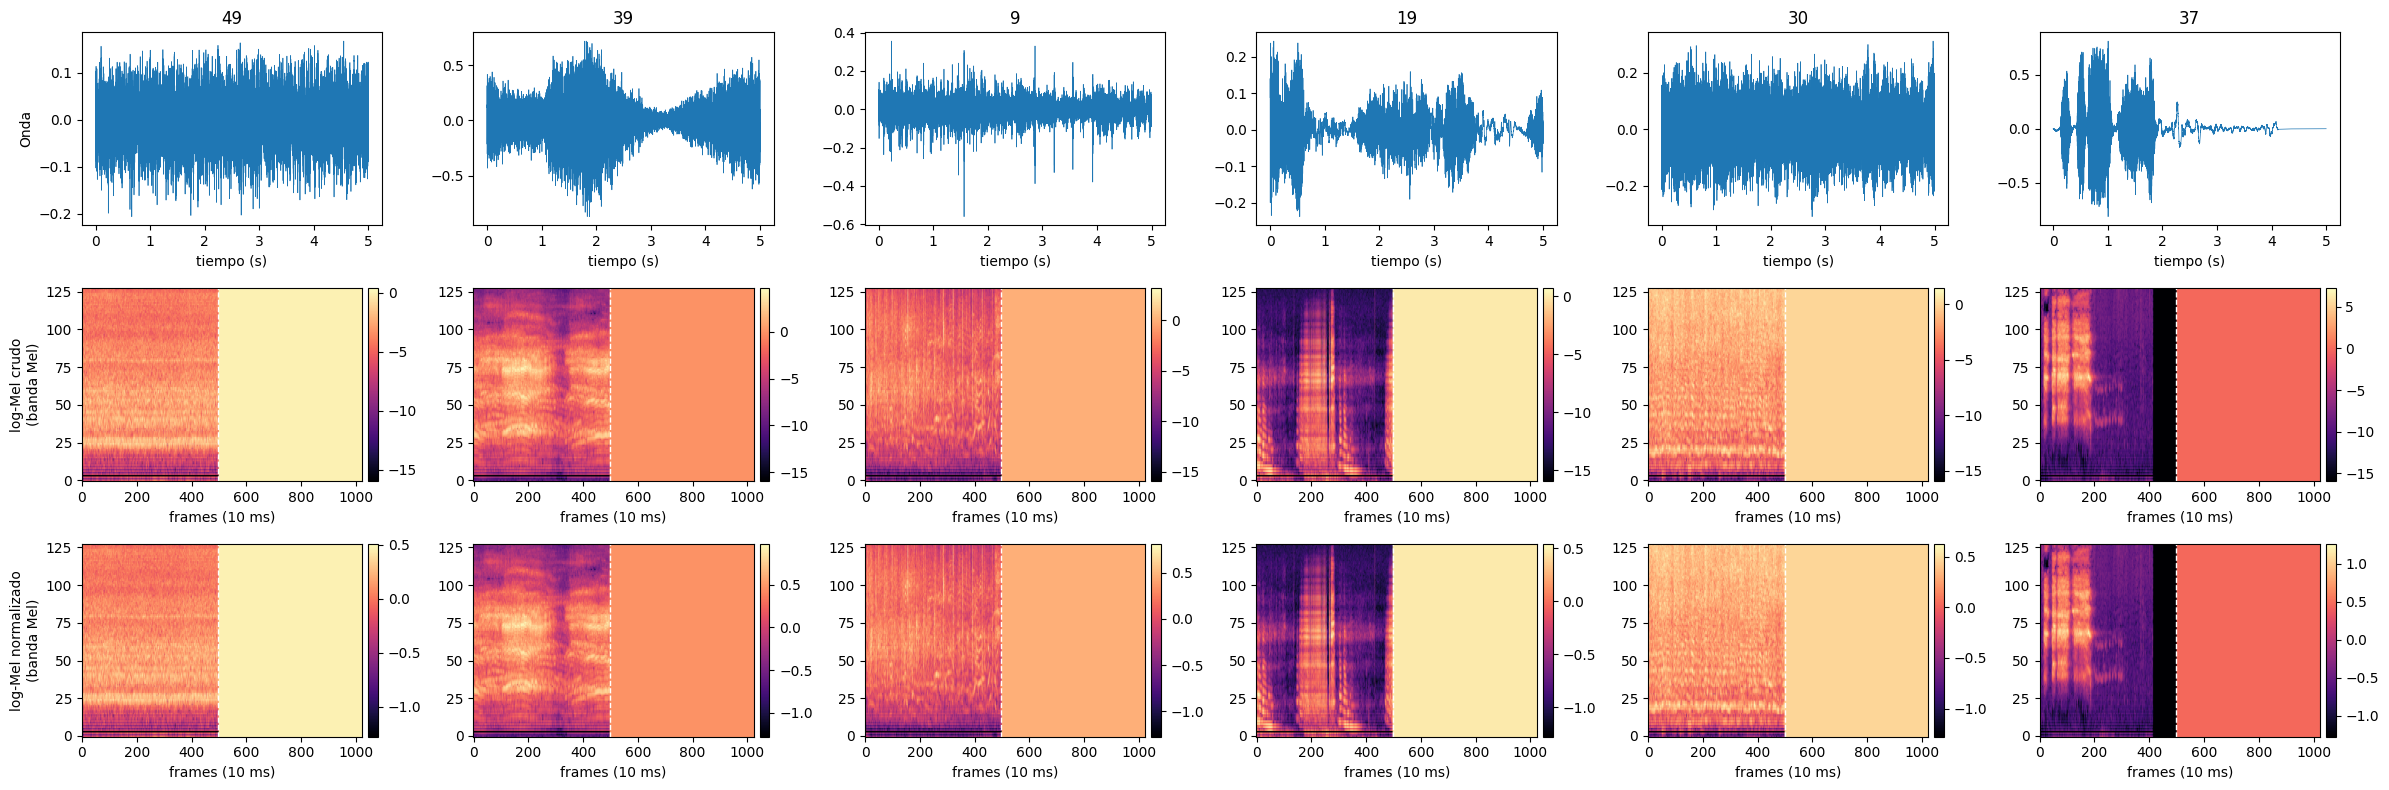

In [14]:
# onda, espectrograma crudo y normalizado de algunos ejemplos
# la línea punteada marca dónde termina la señal y empieza el relleno
def show_examples(ds, n=6):
    idx = np.random.RandomState(0).choice(len(ds), n, replace=False)
    fig, axes = plt.subplots(3, n, figsize=(4 * n, 8))
    for j, i in enumerate(idx):
        a = ds[int(i)]["audio"]; w = load_waveform(a)
        raw  = waveform_to_spectrogram(w, normalize=False)
        norm = waveform_to_spectrogram(w, normalize=True)
        lab = id2label[get_label_id(ds[int(i)])]
        axes[0, j].plot(np.arange(len(w)) / TARGET_SR, w.numpy(), lw=.5); axes[0, j].set_title(lab)
        axes[0, j].set_xlabel("tiempo (s)")
        im1 = axes[1, j].imshow(raw.T, origin="lower", aspect="auto", cmap="magma")
        im2 = axes[2, j].imshow(norm.T, origin="lower", aspect="auto", cmap="magma")
        fig.colorbar(im1, ax=axes[1, j], fraction=.046, pad=.02)
        fig.colorbar(im2, ax=axes[2, j], fraction=.046, pad=.02)
        for ax in axes[1:, j]:
            ax.axvline(VALID_FRAMES, color="white", ls="--", lw=1)
    axes[0, 0].set_ylabel("Onda"); axes[1, 0].set_ylabel("log-Mel crudo\n(banda Mel)")
    axes[2, 0].set_ylabel("log-Mel normalizado\n(banda Mel)")
    for ax in axes[1:].ravel(): ax.set_xlabel("frames (10 ms)")
    plt.tight_layout(); plt.show()

show_examples(dataset)

### 2.2 Aplicación del pipeline a todo el dataset

Aquí se procesan los 1600 audios de train y los 400 de test. Los tensores quedan en memoria (`X_train_spec`, `X_test_spec`) para el DataLoader y también se guardan en `espectrogramas_esc50/`, con una imagen de ejemplo por clase. Si se vuelve a ejecutar la celda, los espectrogramas se leen del disco en lugar de calcularse otra vez.

In [15]:
SPEC_DIR = "espectrogramas_esc50"
X_train_spec, y_train_spec = pipeline.process_dataset(dataset, "train", out_dir=SPEC_DIR)
X_test_spec,  y_test_spec  = pipeline.process_dataset(val_dataset, "test", out_dir=SPEC_DIR)
print("train:", tuple(X_train_spec.shape), "| test:", tuple(X_test_spec.shape))
print("memoria: %.2f GB" % ((X_train_spec.numel() + X_test_spec.numel()) * 4 / 1e9))

train: espectrogramas cargados de espectrogramas_esc50\train.pt
test: espectrogramas cargados de espectrogramas_esc50\test.pt
train: (1600, 1024, 128) | test: (400, 1024, 128)
memoria: 1.05 GB


In [16]:
# control de calidad de la salida del pipeline (todos los archivos):
#  - misma forma (1024, 128) y sin NaN/inf
#  - coincide con el ASTFeatureExtractor de Hugging Face, archivo por archivo
#  - estadísticas de la zona con señal y valor de la zona de relleno
def qc_pipeline(X, ds, name):
    diffs = []
    for i in tqdm(range(len(ds)), desc=f"comparación HF {name}"):
        ref = feature_extractor(load_waveform(ds[i]["audio"]).numpy(), sampling_rate=TARGET_SR,
                                return_tensors="pt")["input_values"][0]
        diffs.append((X[i] - ref).abs().max().item())
    sig, pad = X[:, :VALID_FRAMES], X[:, VALID_FRAMES:]
    return {"split": name, "archivos": len(X), "forma": tuple(X.shape[1:]),
            "todo finito": bool(torch.isfinite(X).all()), "máx |propio - HF|": max(diffs),
            "media (señal)": sig.mean().item(), "std (señal)": sig.std().item(),
            "valor del relleno": np.unique(np.round(pad.numpy(), 4)).tolist()}

qc = pd.DataFrame([qc_pipeline(X_train_spec, dataset, "train"),
                   qc_pipeline(X_test_spec, val_dataset, "test")]).set_index("split")
display(qc)
assert (qc["forma"] == (MAX_FRAMES, N_MELS)).all() and qc["todo finito"].all()
print(f"OK: los {qc['archivos'].sum()} audios quedan en {(MAX_FRAMES, N_MELS)}.")
print(f"El relleno vale {(0 - AST_MEAN) / (2 * AST_STD):.4f} tras normalizar, es decir (0 - media) / (2 * std).")

comparación HF test: 100%|██████████| 400/400 [00:11<00:00, 36.33it/s]


,archivos,forma,todo finito,máx |propio - HF|,media (señal),std (señal),valor del relleno
split,,,,,,,
train,1600,"(1024, 128)",True,0.0,-0.281683,0.587065,[0.46700000762939453]
test,400,"(1024, 128)",True,0.0,-0.282542,0.599864,[0.46700000762939453]


OK: los 2000 audios quedan en (1024, 128).
El relleno vale 0.4670 tras normalizar, es decir (0 - media) / (2 * std).


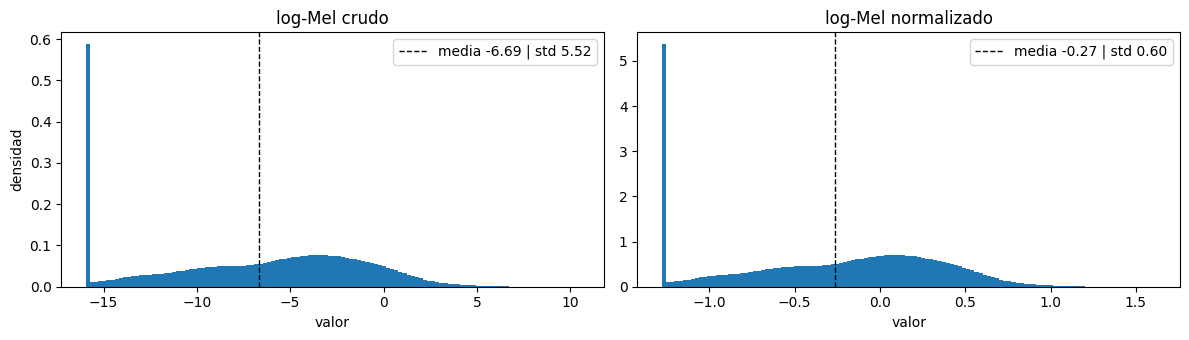

In [17]:
# efecto de la normalización: distribución de valores antes y después (solo frames con señal)
idx = np.random.RandomState(2).choice(len(dataset), min(200, len(dataset)), replace=False)
raw_v, norm_v = [], []
for i in idx:
    w = load_waveform(dataset[int(i)]["audio"])
    raw_v.append(waveform_to_spectrogram(w, normalize=False)[:VALID_FRAMES].flatten())
    norm_v.append(waveform_to_spectrogram(w, normalize=True)[:VALID_FRAMES].flatten())
raw_v, norm_v = torch.cat(raw_v).numpy(), torch.cat(norm_v).numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, v, t in zip(axes, [raw_v, norm_v], ["log-Mel crudo", "log-Mel normalizado"]):
    ax.hist(v, bins=120, density=True, color="tab:blue")
    ax.axvline(v.mean(), color="k", ls="--", lw=1, label=f"media {v.mean():.2f} | std {v.std():.2f}")
    ax.set_title(t); ax.set_xlabel("valor"); ax.legend()
axes[0].set_ylabel("densidad")
plt.tight_layout(); plt.show()

In [18]:
# ¿las entradas están listas para el AST? Se pasan por el checkpoint original (cabeza de
# AudioSet, 527 clases) sin entrenar nada: si el pipeline es correcto, las predicciones
# deben tener sentido para la clase real de ESC-50.
ast_audioset = ASTForAudioClassification.from_pretrained(MODEL_CKPT).to(DEVICE).eval()
idx = np.random.RandomState(3).choice(len(X_test_spec), 8, replace=False)
x = X_test_spec[idx]
print("Lote de entrada al AST:", tuple(x.shape), "(batch, frames, bandas Mel)")
with torch.no_grad():
    p = torch.sigmoid(ast_audioset(input_values=x.to(DEVICE)).logits).cpu()  # AudioSet es multi-etiqueta
rows = []
for k, i in enumerate(idx):
    top = p[k].topk(3)
    rows.append({"clase ESC-50": id2label[int(y_test_spec[i])],
                 "top-3 AudioSet": ", ".join(f"{ast_audioset.config.id2label[int(j)]} ({v:.2f})"
                                             for v, j in zip(top.values, top.indices))})
display(pd.DataFrame(rows))
del ast_audioset
if DEVICE == "cuda": torch.cuda.empty_cache()

Loading weights: 100%|██████████| 203/203 [00:00<00:00, 1009.83it/s]


Lote de entrada al AST: (8, 1024, 128) (batch, frames, bandas Mel)


,clase ESC-50,top-3 AudioSet
0,29,"Chicken, rooster (0.80), Fowl (0.62), Cluck (0..."
1,13,"Cattle, bovinae (0.98), Moo (0.97), Livestock,..."
2,29,"Chicken, rooster (0.58), Speech (0.45), Fowl (..."
3,43,"Thunder (0.33), Thunderstorm (0.26), Explosion..."
4,31,"Typing (0.87), Computer keyboard (0.86), Typew..."
5,24,"Walk, footsteps (0.18), Tap (0.13), Ping (0.05)"
6,6,"Power tool (0.25), Chainsaw (0.21), Tools (0.18)"
7,45,"Train (0.63), Vehicle (0.41), Railroad car, tr..."


### 2.3 Notas sobre el pipeline

Los audios no vienen todos con el mismo formato (ver la tabla de formatos), por eso el paso a mono y a 16 kHz va primero. Después, el relleno o recorte a 1024 frames asegura que el tamaño sea siempre el mismo.

Los clips de ESC-50 duran 5 s, unos 498 frames, así que casi la mitad de la entrada es relleno. Se mantuvo la longitud de 1024 porque es la del checkpoint; con menos frames habría que recortar los embeddings de posición. Como en el AST original, el relleno se hace con ceros sobre el log-Mel antes de normalizar, y al normalizar queda en un valor constante (≈ 0.467), igual para todos los clips, que no aporta información sobre la clase.

Para normalizar se dejaron las estadísticas de AudioSet, que son las que espera el modelo. La documentación de Hugging Face pide que la entrada tenga media 0 y desviación 0.5, y remite al script `get_norm_stats.py` del repositorio del AST para calcular las de otro dataset. En la parte con señal de ESC-50 la media y la desviación se alejan un poco de esos valores (ver la tabla de control), aunque no mucho.

La salida coincide con la del `ASTFeatureExtractor` en todos los archivos, así que entrenar con ella es lo mismo que usar el extractor de Hugging Face. Además, el checkpoint original, sin ningún ajuste, ya reconoce los sonidos a partir de estos espectrogramas, lo que indica que el formato de entrada es el correcto. Los 2000 espectrogramas ocupan cerca de 1 GB (0.5 MB por audio).

### 2.4 Dataset y DataLoader

Cada elemento del `Dataset` devuelve `input_values`, de tamaño (1024, 128), y su etiqueta. El `Dataset` solo envuelve los espectrogramas que ya calculó el pipeline, por lo que no se recalcula nada durante las dos épocas.

In [19]:
class ESC50SpecDataset(Dataset):
    """Envuelve los espectrogramas ya generados por SpectrogramPipeline (sección 2)."""
    def __init__(self, X, y):
        assert X.shape[1:] == (MAX_FRAMES, N_MELS)
        self.cache, self.labels = X, [int(v) for v in y]
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        return {"input_values": self.cache[i], "labels": torch.tensor(self.labels[i])}

train_ds = ESC50SpecDataset(X_train_spec, y_train_spec)
test_ds  = ESC50SpecDataset(X_test_spec,  y_test_spec)

specs_test = X_test_spec   # espectrogramas de test, se usan en las figuras

BATCH_SIZE = 8
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE * 2, shuffle=False)

b = next(iter(train_loader))
print("input_values:", tuple(b["input_values"].shape), "| labels:", tuple(b["labels"].shape))

input_values: (8, 1024, 128) | labels: (8,)


## 3. Creación del modelo

Se usa `ASTForAudioClassification` de Transformers con el checkpoint `MIT/ast-finetuned-audioset-10-10-0.4593` [3], preentrenado en AudioSet. El modelo tiene cuatro partes:

1. Embedding de parches: el espectrograma de 1024 x 128 se corta en parches de 16 x 16 con paso 10 en tiempo y en frecuencia, es decir, parches solapados, 101 x 12 = 1212 en total. Cada parche se proyecta linealmente a un vector de 768 dimensiones, como en el Vision Transformer [6].
2. Tokens especiales y posición: se añaden un token CLS y uno de destilación, heredados de DeiT, y cada token lleva un embedding de posición aprendido.
3. Codificador: 12 capas de transformer con 12 cabezas de auto-atención [2] cada una.
4. Cabeza de clasificación: una LayerNorm y una capa lineal sobre el promedio de los tokens CLS y de destilación.

La cabeza original tiene 527 salidas, una por clase de AudioSet. Con `ignore_mismatched_sizes=True` se cambia por una de 50 salidas, las clases de ESC-50. Esa capa arranca con pesos aleatorios; el resto del modelo conserva los pesos preentrenados, aunque también se ajusta durante el entrenamiento.

In [20]:
def build_model():
    """AST preentrenado en AudioSet con la cabeza de clasificación cambiada de 527 a 50 clases."""
    return ASTForAudioClassification.from_pretrained(
        MODEL_CKPT, num_labels=NUM_LABELS, id2label=id2label, label2id=label2id,
        ignore_mismatched_sizes=True)

model_demo = build_model().to(DEVICE)
cfg = model_demo.config
f_out = (cfg.num_mel_bins - cfg.patch_size) // cfg.frequency_stride + 1
t_out = (cfg.max_length - cfg.patch_size) // cfg.time_stride + 1
n_total = sum(p.numel() for p in model_demo.parameters())
n_head = sum(p.numel() for p in model_demo.classifier.parameters())
display(pd.DataFrame({"valor": {
    "entrada (frames x bandas Mel)": f"{cfg.max_length} x {cfg.num_mel_bins}",
    "parche / paso (tiempo, frec.)": f"{cfg.patch_size} x {cfg.patch_size} / ({cfg.time_stride}, {cfg.frequency_stride})",
    "parches (tiempo x frec.)": f"{t_out} x {f_out} = {t_out * f_out}",
    "tokens (parches + CLS + destilación)": t_out * f_out + 2,
    "dimensión oculta": cfg.hidden_size,
    "capas / cabezas de atención": f"{cfg.num_hidden_layers} / {cfg.num_attention_heads}",
    "clases de salida": cfg.num_labels,
    "parámetros totales": f"{n_total / 1e6:.1f} M",
    "parámetros de la cabeza nueva": f"{n_head:,}"}}))
print(model_demo.classifier)

# prueba con un lote del DataLoader: debe devolver (batch, 50) logits
with torch.no_grad():
    out = model_demo(input_values=b["input_values"].to(DEVICE))
print("entrada:", tuple(b["input_values"].shape), "-> logits:", tuple(out.logits.shape))
del model_demo, out
if DEVICE == "cuda": torch.cuda.empty_cache()

[transformers] You passed `num_labels=50` which is incompatible to the `id2label` map of length `527`.
Loading weights: 100%|██████████| 203/203 [00:00<00:00, 1364.57it/s]
[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                          
------------------------+----------+------------------------------------------------------------------------------------------
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([50])          
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([50, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


,valor
entrada (frames x bandas Mel),1024 x 128
"parche / paso (tiempo, frec.)","16 x 16 / (10, 10)"
parches (tiempo x frec.),101 x 12 = 1212
tokens (parches + CLS + destilación),1214
dimensión oculta,768
capas / cabezas de atención,12 / 12
clases de salida,50
parámetros totales,86.2 M
parámetros de la cabeza nueva,"39,986"


ASTMLPHead(
  (layernorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
  (dense): Linear(in_features=768, out_features=50, bias=True)
)
entrada: (8, 1024, 128) -> logits: (8, 50)


## 4. Entrenamiento del modelo preentrenado

Se parte del modelo de la sección 3 y se ajustan todas sus capas durante 2 épocas con AdamW [7], una tasa de aprendizaje de 5e-5 y weight decay de 0.01. La tasa sube linealmente durante el primer 10 % de los pasos y luego baja, también linealmente, hasta cero. Este warm-up evita que las primeras actualizaciones, cuando la cabeza nueva todavía es aleatoria, dañen los pesos preentrenados. Los lotes son de 8 espectrogramas, el gradiente se recorta a norma 1.0 y, cuando hay GPU, se entrena con precisión mixta para ahorrar memoria y tiempo.

Con un solo entrenamiento no se sabe cuánto cambia el resultado de una corrida a otra. Por eso se repite con tres semillas (42, 43 y 44), sin cambiar nada más, y se reportan la media y la desviación estándar. Las métricas, el análisis por clase y la matriz de confusión usan los tres modelos; los ejemplos de errores, el t-SNE y los mapas de atención usan solo el de la semilla 42.

### 4.1 Fine-tuning con 3 semillas

In [21]:
from transformers import get_linear_schedule_with_warmup

EPOCHS, LR = 2, 5e-5
y_test = np.array(test_ds.labels)

@torch.no_grad()
def predict_logits(loader, mdl):
    mdl.eval(); out = []
    for b in loader:
        with torch.autocast(device_type=DEVICE, enabled=(DEVICE == "cuda")):
            out.append(mdl(input_values=b["input_values"].to(DEVICE)).logits.float().cpu())
    return torch.cat(out)

def spec_augment(x, max_freq=24, max_time=96, valid_frames=VALID_FRAMES):
    """Una máscara de frecuencia y una de tiempo por espectrograma (x: batch, 1024, 128).
    Solo se usa en la variante con SpecAugment (sección 4.2)."""
    x = x.clone()
    n_bins = x.shape[2]
    for i in range(x.shape[0]):
        f = int(torch.randint(0, max_freq + 1, (1,)))
        f0 = int(torch.randint(0, n_bins - f + 1, (1,)))
        t = int(torch.randint(0, max_time + 1, (1,)))
        t0 = int(torch.randint(0, max(1, valid_frames - t), (1,)))
        x[i, :, f0:f0 + f] = 0     # tras normalizar, 0 es aproximadamente la media
        x[i, t0:t0 + t, :] = 0
    return x

def finetune(use_specaug, seed, keep_model=False):
    set_seed(seed)
    m = build_model().to(DEVICE)
    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    opt = torch.optim.AdamW(m.parameters(), lr=LR, weight_decay=0.01)
    steps = EPOCHS * len(loader)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    scl = torch.cuda.amp.GradScaler(enabled=(DEVICE == "cuda"))
    hist = {"train_loss": [], "test_acc": []}
    for ep in range(EPOCHS):
        m.train(); run = 0.0
        for b in loader:
            x = spec_augment(b["input_values"]) if use_specaug else b["input_values"]
            opt.zero_grad()
            with torch.autocast(device_type=DEVICE, enabled=(DEVICE == "cuda")):
                out = m(input_values=x.to(DEVICE), labels=b["labels"].to(DEVICE))
            scl.scale(out.loss).backward(); scl.unscale_(opt)
            nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            scl.step(opt); scl.update(); sched.step(); run += out.loss.item()
        yp = predict_logits(test_loader, m).argmax(-1).numpy()
        hist["train_loss"].append(run / len(loader)); hist["test_acc"].append(accuracy_score(y_test, yp))
        print(f"SpecAugment={use_specaug} | semilla {seed} | época {ep+1}: "
              f"loss {hist['train_loss'][-1]:.4f} | acc test {hist['test_acc'][-1]:.4f}")
    if keep_model:
        return yp, hist, m
    del m
    if DEVICE == "cuda": torch.cuda.empty_cache()
    return yp, hist, None

def predict(loader):
    """Etiquetas y predicciones del modelo principal (semilla 42)."""
    ys = np.concatenate([b["labels"].numpy() for b in loader])
    return ys, predict_logits(loader, model).argmax(-1).numpy()

In [22]:
# entrenamiento con las 3 semillas; se conserva el modelo de la primera
CFG_FT, CFG_SA = "AST ajustado", "AST ajustado + SpecAugment"
runs  = {CFG_FT: {}, CFG_SA: {}}     # predicciones en test por configuración y semilla
hists = {CFG_FT: {}, CFG_SA: {}}     # loss y accuracy por época

for s in SEEDS:
    runs[CFG_FT][s], hists[CFG_FT][s], m_ = finetune(False, s, keep_model=(s == SEED))
    if s == SEED:
        model = m_


[transformers] You passed `num_labels=50` which is incompatible to the `id2label` map of length `527`.
Loading weights: 100%|██████████| 203/203 [00:00<00:00, 1182.93it/s]
[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                          
------------------------+----------+------------------------------------------------------------------------------------------
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([50])          
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([50, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


SpecAugment=False | semilla 42 | época 1: loss 1.1549 | acc test 0.8925


[transformers] You passed `num_labels=50` which is incompatible to the `id2label` map of length `527`.


SpecAugment=False | semilla 42 | época 2: loss 0.0695 | acc test 0.9275


Loading weights: 100%|██████████| 203/203 [00:00<00:00, 850.26it/s]
[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                          
------------------------+----------+------------------------------------------------------------------------------------------
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([50])          
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([50, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


SpecAugment=False | semilla 43 | época 1: loss 1.1840 | acc test 0.8975
SpecAugment=False | semilla 43 | época 2: loss 0.0586 | acc test 0.9250


[transformers] You passed `num_labels=50` which is incompatible to the `id2label` map of length `527`.
Loading weights: 100%|██████████| 203/203 [00:00<00:00, 954.70it/s]
[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                          
------------------------+----------+------------------------------------------------------------------------------------------
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([50])          
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([50, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


SpecAugment=False | semilla 44 | época 1: loss 1.1582 | acc test 0.8875
SpecAugment=False | semilla 44 | época 2: loss 0.0620 | acc test 0.9475


In [23]:
# guardo el modelo de la primera semilla, se usa en la evaluación y en los resultados
FT_DIR = "ast_esc50_finetuned"
model.save_pretrained(FT_DIR)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.89it/s]


### 4.2 Variante con SpecAugment

Para la comparación de la sección 6 se entrena también una variante idéntica, pero con SpecAugment [8]: en cada lote se tapa una franja de frecuencias y una de tiempo en cada espectrograma. La figura muestra el efecto sobre un espectrograma de test. Al final están las curvas de loss y accuracy por época de las dos variantes.

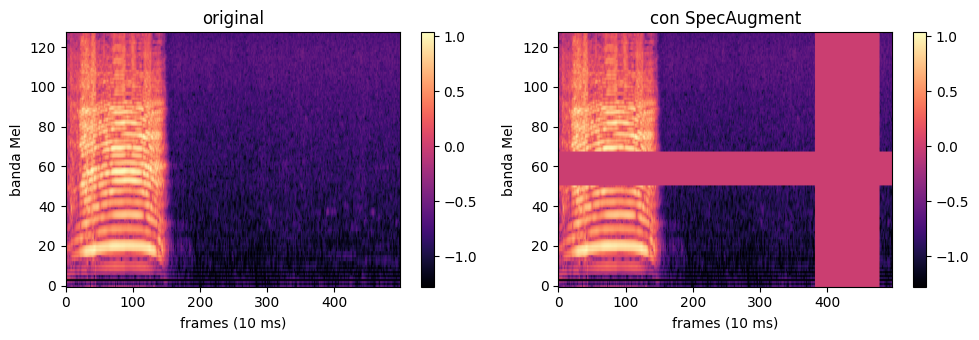

In [24]:
# ejemplo de SpecAugment sobre un espectrograma de test
set_seed()
x0 = specs_test[:1]
x1 = spec_augment(x0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, x, t in zip(axes, [x0, x1], ["original", "con SpecAugment"]):
    im = ax.imshow(x[0][:VALID_FRAMES].T, origin="lower", aspect="auto", cmap="magma")
    ax.set_title(t); ax.set_xlabel("frames (10 ms)"); ax.set_ylabel("banda Mel")
    fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()


[transformers] You passed `num_labels=50` which is incompatible to the `id2label` map of length `527`.
Loading weights: 100%|██████████| 203/203 [00:00<00:00, 1021.05it/s]
[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                          
------------------------+----------+------------------------------------------------------------------------------------------
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([50])          
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([50, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


SpecAugment=True | semilla 42 | época 1: loss 1.2634 | acc test 0.9000
SpecAugment=True | semilla 42 | época 2: loss 0.1275 | acc test 0.9400


[transformers] You passed `num_labels=50` which is incompatible to the `id2label` map of length `527`.
Loading weights: 100%|██████████| 203/203 [00:00<00:00, 831.41it/s]
[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                          
------------------------+----------+------------------------------------------------------------------------------------------
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([50])          
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([50, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


SpecAugment=True | semilla 43 | época 1: loss 1.2790 | acc test 0.8675
SpecAugment=True | semilla 43 | época 2: loss 0.1035 | acc test 0.9575


[transformers] You passed `num_labels=50` which is incompatible to the `id2label` map of length `527`.
Loading weights: 100%|██████████| 203/203 [00:00<00:00, 1053.44it/s]
[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                          
------------------------+----------+------------------------------------------------------------------------------------------
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([50])          
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([50, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


SpecAugment=True | semilla 44 | época 1: loss 1.2175 | acc test 0.8850
SpecAugment=True | semilla 44 | época 2: loss 0.1007 | acc test 0.9325


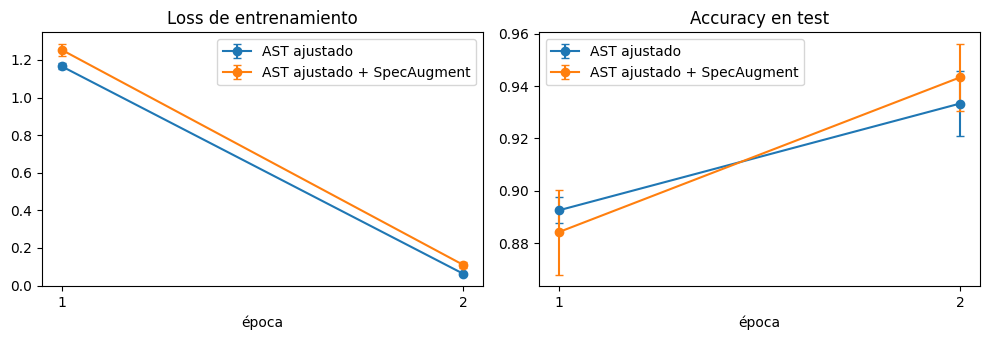

In [25]:
# SpecAugment con las mismas semillas
for s in SEEDS:
    runs[CFG_SA][s], hists[CFG_SA][s], _ = finetune(True, s)

# curvas de entrenamiento por época: media y desviación entre semillas
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
ep = list(range(1, EPOCHS + 1))
for k in runs:
    L = np.array([hists[k][s]["train_loss"] for s in SEEDS]); A = np.array([hists[k][s]["test_acc"] for s in SEEDS])
    axes[0].errorbar(ep, L.mean(0), yerr=L.std(0, ddof=1), marker="o", capsize=3, label=k)
    axes[1].errorbar(ep, A.mean(0), yerr=A.std(0, ddof=1), marker="o", capsize=3, label=k)
axes[0].set_title("Loss de entrenamiento"); axes[1].set_title("Accuracy en test")
for ax in axes: ax.set_xlabel("época"); ax.set_xticks(ep); ax.legend()
plt.tight_layout(); plt.show()

## 5. Evaluación del modelo

Se usan los tres modelos entrenados (semillas 42, 43 y 44). Las métricas se calculan sobre el test con scikit-learn para cada modelo y se reporta la media ± la desviación estándar entre semillas. Las matrices de confusión suman las predicciones de los tres modelos, de modo que cada audio de test cuenta tres veces.

In [26]:
# métricas globales por semilla y media ± desviación estándar entre semillas
NAMES = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]
y_true = y_test
labels_present = list(range(NUM_LABELS))
preds_ft = [runs[CFG_FT][s] for s in SEEDS]          # predicciones en test de cada semilla

def core_metrics(yt, yp):
    p_, r_, f_, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
    return np.array([accuracy_score(yt, yp), p_, r_, f_])

def all_metrics(yt, yp):
    pw, rw, fw, _ = precision_recall_fscore_support(yt, yp, average="weighted", zero_division=0)
    return list(core_metrics(yt, yp)) + [pw, rw, fw]

por_semilla = pd.DataFrame([all_metrics(y_true, p) for p in preds_ft], index=[f"semilla {s}" for s in SEEDS],
                           columns=NAMES + ["Precision (weighted)", "Recall (weighted)", "F1 (weighted)"])
resumen = por_semilla.copy()
resumen.loc["media"] = por_semilla.mean()
resumen.loc["desv. estándar"] = por_semilla.std(ddof=1)
display(resumen.round(4))
for nm_ in por_semilla.columns:
    print(f"{nm_:22s}: {por_semilla[nm_].mean():.4f} ± {por_semilla[nm_].std(ddof=1):.4f}")

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted)
semilla 42,0.9275,0.9355,0.9275,0.9227,0.9355,0.9275,0.9227
semilla 43,0.9250,0.9312,0.9250,0.9199,0.9312,0.9250,0.9199
semilla 44,0.9475,0.9551,0.9475,0.9441,0.9551,0.9475,0.9441
media,0.9333,0.9406,0.9333,0.9289,0.9406,0.9333,0.9289
desv. estándar,0.0123,0.0127,0.0123,0.0133,0.0127,0.0123,0.0133


Accuracy              : 0.9333 ± 0.0123
Precision (macro)     : 0.9406 ± 0.0127
Recall (macro)        : 0.9333 ± 0.0123
F1 (macro)            : 0.9289 ± 0.0133
Precision (weighted)  : 0.9406 ± 0.0127
Recall (weighted)     : 0.9333 ± 0.0123
F1 (weighted)         : 0.9289 ± 0.0133


In [27]:
# reporte por clase: precision, recall y F1 de cada semilla, resumidos como media ± desviación
prf = np.stack([np.stack(precision_recall_fscore_support(y_true, p, labels=labels_present, zero_division=0)[:3])
                for p in preds_ft])                     # (semillas, 3 métricas, clases)
mean_c, std_c = prf.mean(0), prf.std(0, ddof=1)
soporte = np.bincount(y_true, minlength=NUM_LABELS)
df_cls = pd.DataFrame({"clase": CLASS_NAMES,
                       "precision": mean_c[0], "precision_std": std_c[0],
                       "recall": mean_c[1], "recall_std": std_c[1],
                       "f1": mean_c[2], "f1_std": std_c[2], "soporte": soporte})
reporte = pd.DataFrame({"clase": CLASS_NAMES, "soporte": soporte,
                        **{m: [f"{a:.3f} ± {b:.3f}" for a, b in zip(mean_c[k], std_c[k])]
                           for k, m in enumerate(["precision", "recall", "f1"])}}).set_index("clase")
pd.set_option("display.max_rows", 60)
display(reporte)

,soporte,precision,recall,f1
clase,,,,
0,8,1.000 ± 0.000,0.833 ± 0.072,0.908 ± 0.044
1,8,0.933 ± 0.115,0.958 ± 0.072,0.941 ± 0.056
10,8,0.963 ± 0.064,1.000 ± 0.000,0.980 ± 0.034
11,8,1.000 ± 0.000,0.958 ± 0.072,0.978 ± 0.038
12,8,0.958 ± 0.072,0.875 ± 0.000,0.914 ± 0.034
13,8,1.000 ± 0.000,0.958 ± 0.072,0.978 ± 0.038
14,8,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
15,8,0.859 ± 0.122,0.917 ± 0.072,0.882 ± 0.055
16,8,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000


Peores 10 clases (F1 medio):


,clase,precision,recall,f1,f1_std,soporte
21,28,0.643,0.500,0.556,0.234,8
42,47,0.790,0.458,0.565,0.044,8
17,24,0.952,0.500,0.630,0.147,8
44,49,0.944,0.500,0.642,0.087,8
15,22,0.633,0.917,0.745,0.089,8
16,23,0.800,0.875,0.830,0.090,8
9,17,1.000,0.792,0.875,0.116,8
7,15,0.859,0.917,0.882,0.055,8
41,46,0.825,0.958,0.884,0.008,8
32,38,0.815,1.000,0.894,0.082,8


Mejores 10 clases (F1 medio):


,clase,precision,recall,f1,f1_std,soporte
49,9,1.0,1.0,1.0,0.0,8
48,8,1.0,1.0,1.0,0.0,8
47,7,1.0,1.0,1.0,0.0,8
34,4,1.0,1.0,1.0,0.0,8
33,39,1.0,1.0,1.0,0.0,8
39,44,1.0,1.0,1.0,0.0,8
35,40,1.0,1.0,1.0,0.0,8
8,16,1.0,1.0,1.0,0.0,8
11,19,1.0,1.0,1.0,0.0,8
6,14,1.0,1.0,1.0,0.0,8


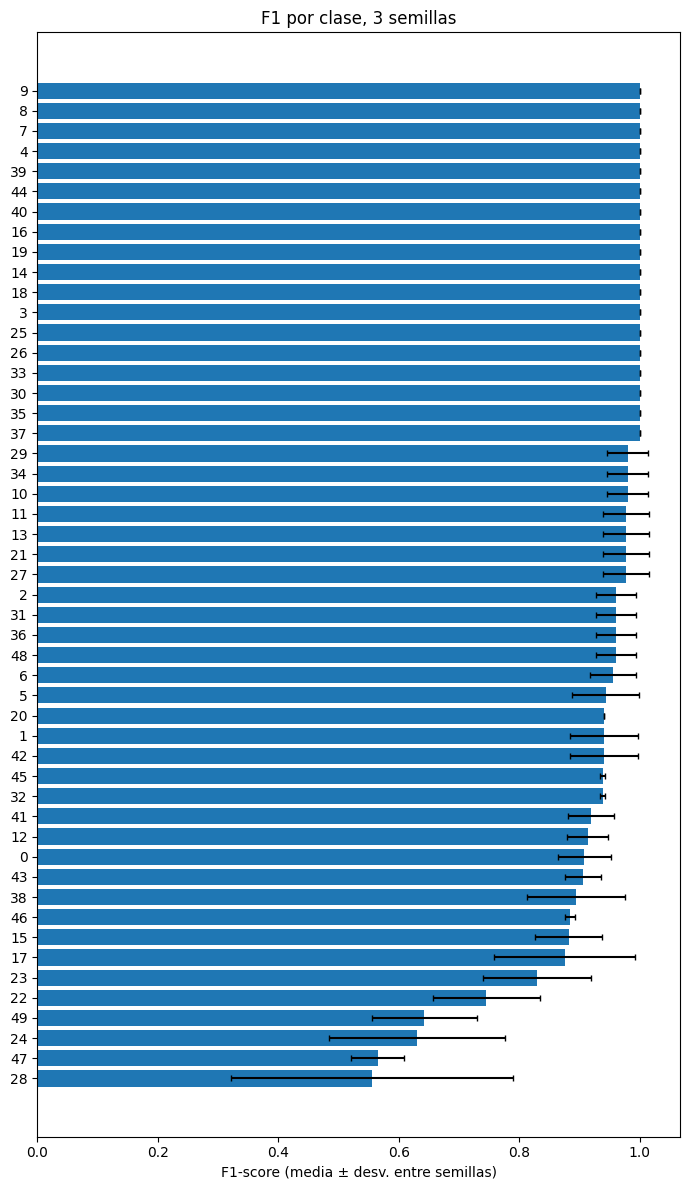

In [28]:
# mejores y peores clases según el F1 medio de las 3 semillas
df_cls = df_cls.sort_values("f1")
cols = ["clase", "precision", "recall", "f1", "f1_std", "soporte"]
print("Peores 10 clases (F1 medio):");  display(df_cls[cols].head(10).round(3))
print("Mejores 10 clases (F1 medio):"); display(df_cls[cols].tail(10).iloc[::-1].round(3))

plt.figure(figsize=(7, 12))
plt.barh(df_cls["clase"], df_cls["f1"], xerr=df_cls["f1_std"], capsize=2)
plt.xlabel("F1-score (media ± desv. entre semillas)"); plt.title("F1 por clase, 3 semillas")
plt.tight_layout(); plt.show()

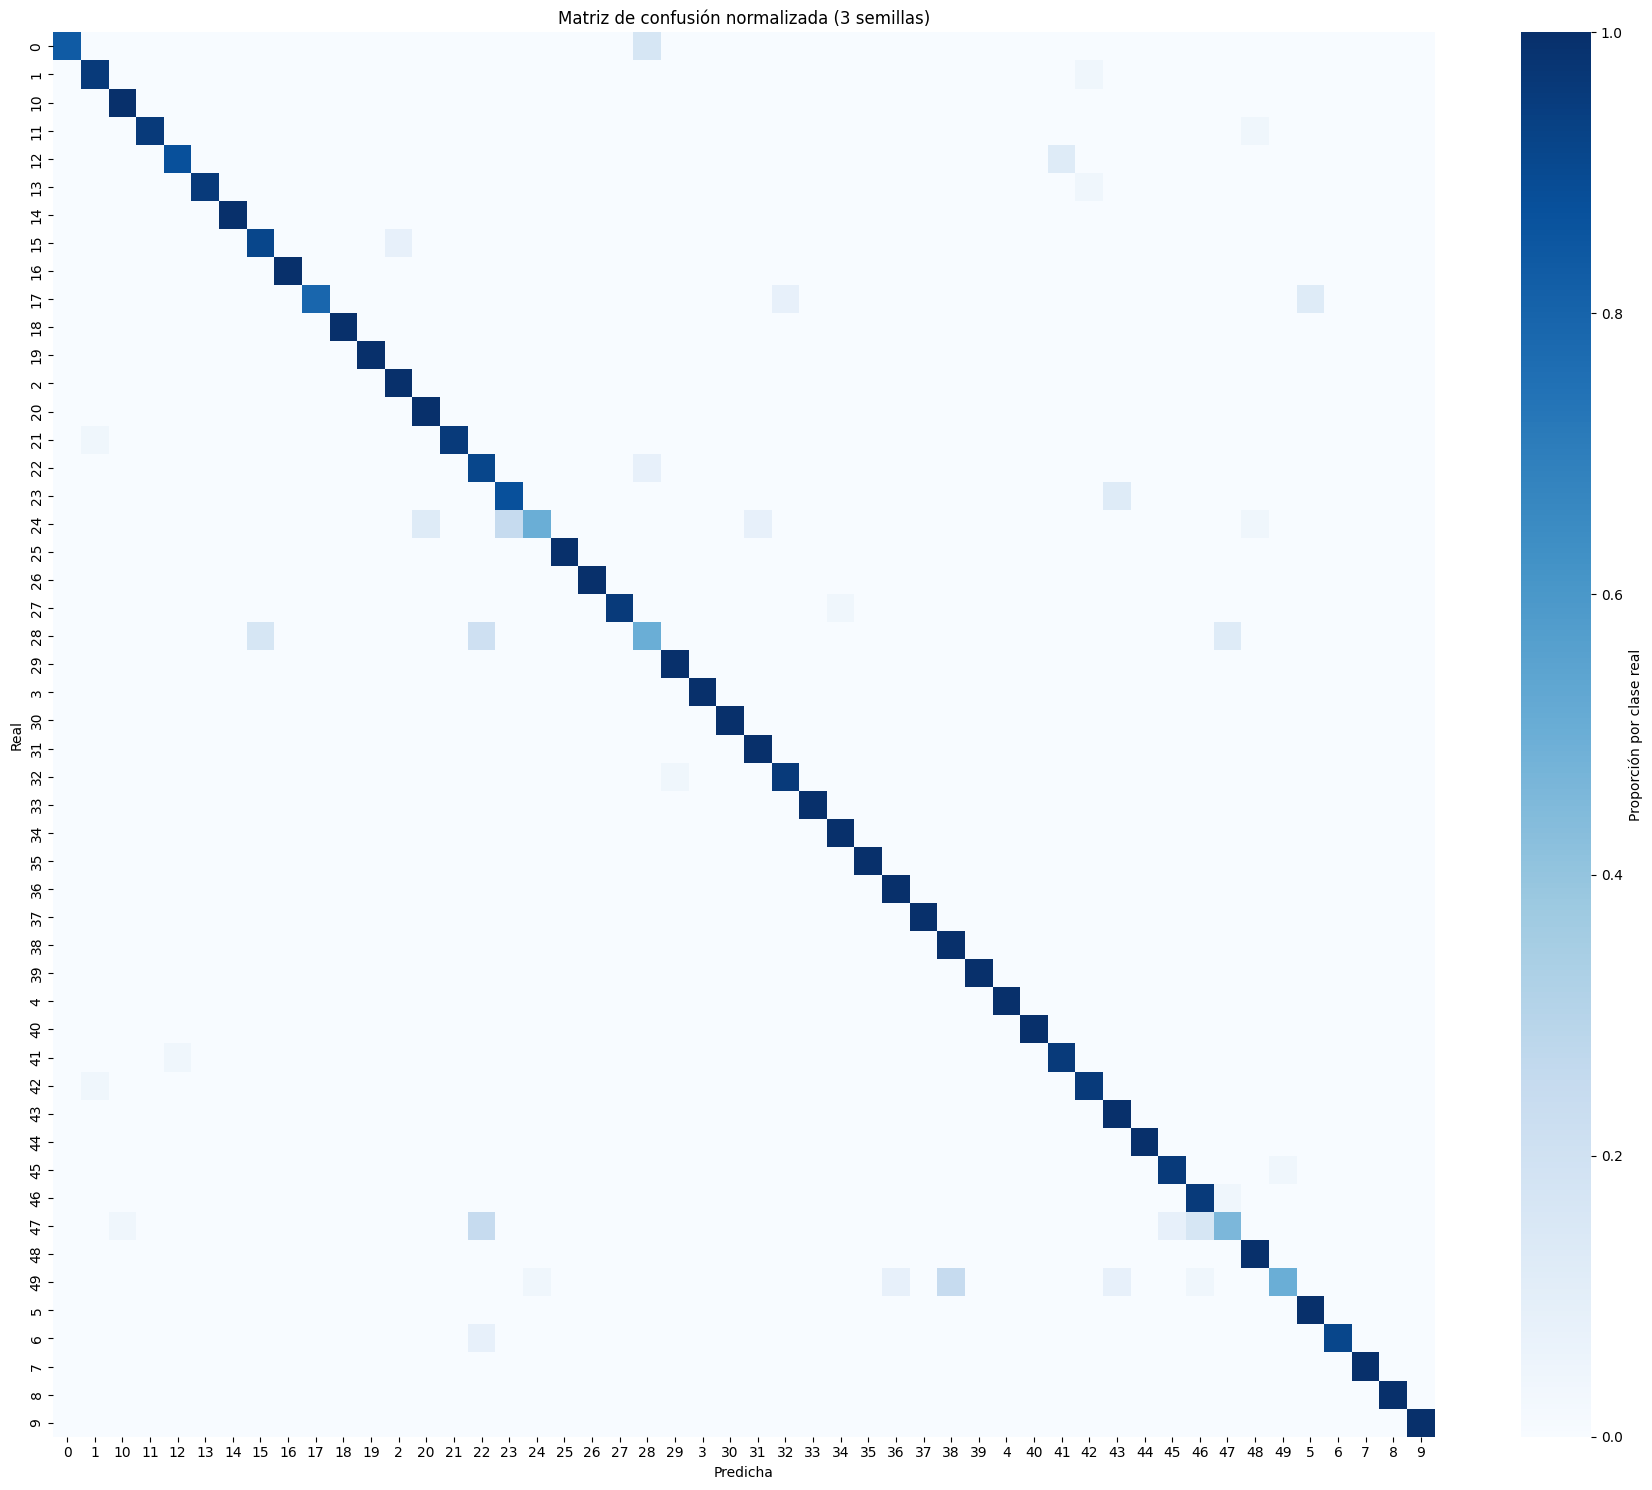

Pares más confundidos (3 semillas):


,real,predicha,errores (media),errores (desv.),semillas con el error
25,47,22,2.00,0.00,3
30,49,38,2.00,1.73,3
12,24,23,2.00,1.73,2
17,28,22,1.67,2.08,2
0,0,28,1.33,0.58,3
27,47,46,1.33,0.58,3
16,28,15,1.33,1.15,2
3,12,41,1.00,0.00,3
10,23,43,1.00,0.00,3
11,24,20,1.00,0.00,3


In [29]:
# matriz de confusión promedio de las 3 semillas, normalizada por fila
cm_seeds = np.stack([confusion_matrix(y_true, p, labels=labels_present) for p in preds_ft])   # (semillas, 50, 50)
cm = cm_seeds.sum(0)
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
plt.figure(figsize=(18, 15))
sns.heatmap(cm_norm, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap="Blues", vmin=0, vmax=1,
            cbar_kws={"label": "Proporción por clase real"})
plt.xlabel("Predicha"); plt.ylabel("Real"); plt.title("Matriz de confusión normalizada (3 semillas)")
plt.tight_layout(); plt.show()

# pares de clases más confundidos: errores por semilla (media ± desviación) y en cuántas semillas aparecen
off_s = cm_seeds.copy()
for o in off_s: np.fill_diagonal(o, 0)
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], off_s[:, i, j].mean(), off_s[:, i, j].std(ddof=1), int((off_s[:, i, j] > 0).sum()))
         for i in range(NUM_LABELS) for j in range(NUM_LABELS) if off_s[:, i, j].sum() > 0]
top = (pd.DataFrame(pairs, columns=["real", "predicha", "errores (media)", "errores (desv.)", "semillas con el error"])
       .sort_values(["errores (media)", "semillas con el error"], ascending=False).head(15))
print("Pares más confundidos (3 semillas):"); display(top.round(2))

Accuracy a nivel macro-categoría: 0.9500 ± 0.0109


,F1 (media),F1 (desv.)
Animales,0.947,0.014
Paisajes naturales y agua,0.949,0.013
Humanos (no habla),0.954,0.024
Doméstico / interior,0.960,0.003
Urbano / exterior,0.940,0.007


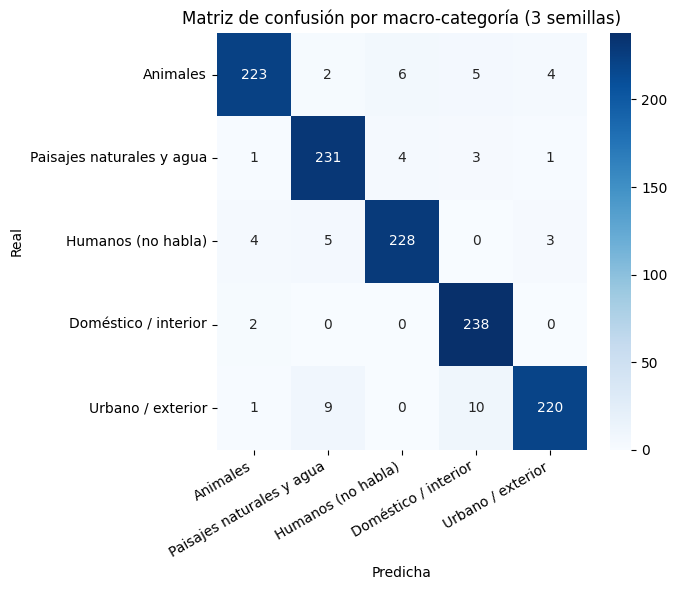

In [30]:
# agrupo las clases en las 5 categorías de ESC-50 (clase // 10)
MACRO = ["Animales", "Paisajes naturales y agua", "Humanos (no habla)", "Doméstico / interior", "Urbano / exterior"]
macro_true = y_true // 10
acc_m = [accuracy_score(macro_true, p // 10) for p in preds_ft]
f1_m = np.stack([precision_recall_fscore_support(macro_true, p // 10, labels=range(5), zero_division=0)[2] for p in preds_ft])
print("Accuracy a nivel macro-categoría: %.4f ± %.4f" % (np.mean(acc_m), np.std(acc_m, ddof=1)))
display(pd.DataFrame({"F1 (media)": f1_m.mean(0), "F1 (desv.)": f1_m.std(0, ddof=1)}, index=MACRO).round(3))

cm_m = sum(confusion_matrix(macro_true, p // 10, labels=range(5)) for p in preds_ft)
plt.figure(figsize=(7, 6))
sns.heatmap(cm_m, annot=True, fmt="d", cmap="Blues", xticklabels=MACRO, yticklabels=MACRO)
plt.xlabel("Predicha"); plt.ylabel("Real"); plt.title("Matriz de confusión por macro-categoría (3 semillas)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

## 6. Resultados cuantitativos

Aquí también se usan los tres modelos (semillas 42, 43 y 44). A las métricas de la sección 5 se les añade su incertidumbre, con intervalos de confianza por bootstrap sobre el test, y se comparan tres configuraciones. Para el linear probe de esa comparación primero se extraen los embeddings del AST sin ajustar. En la misma celda se extraen los del modelo ajustado con la semilla 42, que solo se usan en el t-SNE de los resultados cualitativos.

### 6.1 Embeddings del AST antes y después del fine-tuning

In [31]:
from transformers import ASTModel
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

@torch.no_grad()
def extract_embeddings(backbone, loader):
    backbone.eval(); embs = []
    for b in loader:
        with torch.autocast(device_type=DEVICE, enabled=(DEVICE == "cuda")):
            embs.append(backbone(input_values=b["input_values"].to(DEVICE)).pooler_output.float().cpu())
    return torch.cat(embs).numpy()

# embeddings del modelo ya ajustado
emb_after = extract_embeddings(model.audio_spectrogram_transformer, test_loader)
# y del modelo preentrenado sin ajustar
base_backbone = ASTModel.from_pretrained(MODEL_CKPT).to(DEVICE)
emb_before = extract_embeddings(base_backbone, test_loader)
del base_backbone
print(emb_before.shape, emb_after.shape)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 763.03it/s]
[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.layernorm.bias   | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


(400, 768) (400, 768)


### 6.2 Intervalos de confianza con bootstrap

El bootstrap [9] se hace sobre el conjunto de test: 1000 veces se remuestrean los ejemplos con reemplazo y se recalculan las métricas. En cada remuestreo se calculan las métricas de las 3 semillas y se promedian, así que el intervalo es el de la media entre semillas. El IC de 95 % sale de los percentiles 2.5 y 97.5. Se calcula para accuracy, precision, recall y F1 (macro y ponderados) y para el F1 de cada clase. Por separado se da la desviación estándar entre semillas, que refleja la variabilidad del entrenamiento.

In [32]:
B, ALPHA = 1000, 0.05
rng = np.random.default_rng(SEED)
n = len(y_true)

def metrics_fn(yt, yp):
    pm, rm, fm, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(yt, yp, average="weighted", zero_division=0)
    return {"Accuracy": accuracy_score(yt, yp),
            "Precision (macro)": pm, "Recall (macro)": rm, "F1 (macro)": fm,
            "Precision (weighted)": pw, "Recall (weighted)": rw, "F1 (weighted)": fw}

por_semilla_m = pd.DataFrame([metrics_fn(y_true, p) for p in preds_ft])
point = por_semilla_m.mean().to_dict()                  # media entre semillas
sd_semillas = por_semilla_m.std(ddof=1).to_dict()       # desviación entre semillas
boot = {k: np.empty(B) for k in point}
boot_f1_cls = np.empty((B, NUM_LABELS))

for b in range(B):
    idx = rng.integers(0, n, n)  # con reemplazo
    yt = y_true[idx]
    res = pd.DataFrame([metrics_fn(yt, p[idx]) for p in preds_ft]).mean()   # media entre semillas
    for k in point:
        boot[k][b] = res[k]
    boot_f1_cls[b] = np.mean([precision_recall_fscore_support(yt, p[idx], labels=labels_present,
                                                             zero_division=0)[2] for p in preds_ft], axis=0)

rows = []
for k in point:
    lo, hi = np.percentile(boot[k], [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)])
    rows.append({"Métrica": k, "Media (3 semillas)": point[k], "IC95% inf": lo, "IC95% sup": hi,
                 "Error estándar (bootstrap)": boot[k].std(ddof=1),
                 "Desv. entre semillas": sd_semillas[k]})
df_ci = pd.DataFrame(rows).set_index("Métrica")
display(df_ci.round(4))

,Media (3 semillas),IC95% inf,IC95% sup,Error estándar (bootstrap),Desv. entre semillas
Métrica,,,,,
Accuracy,0.9333,0.9133,0.9517,0.0103,0.0123
Precision (macro),0.9406,0.9185,0.9547,0.0093,0.0127
Recall (macro),0.9333,0.9167,0.9494,0.0084,0.0123
F1 (macro),0.9289,0.9046,0.9434,0.0099,0.0133
Precision (weighted),0.9406,0.9273,0.9611,0.0088,0.0127
Recall (weighted),0.9333,0.9133,0.9517,0.0103,0.0123
F1 (weighted),0.9289,0.9056,0.9494,0.0114,0.0133


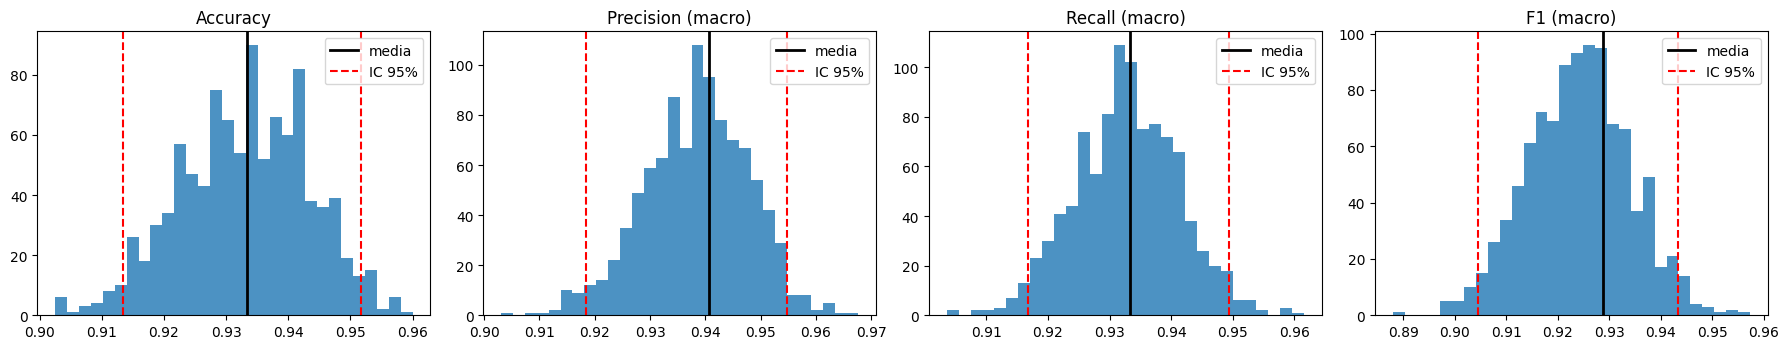

In [33]:
# distribución bootstrap de las métricas principales
keys = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, k in zip(axes, keys):
    ax.hist(boot[k], bins=30, alpha=.8)
    lo, hi = df_ci.loc[k, ["IC95% inf", "IC95% sup"]]
    ax.axvline(point[k], color="k", lw=2, label="media")
    ax.axvline(lo, color="r", ls="--"); ax.axvline(hi, color="r", ls="--", label="IC 95%")
    ax.set_title(k); ax.legend()
plt.tight_layout(); plt.show()

,clase,F1,IC95% inf,IC95% sup
21,28,0.556,0.243,0.778
42,47,0.565,0.176,0.786
17,24,0.630,0.250,0.867
44,49,0.642,0.250,0.872
15,22,0.745,0.497,0.892
16,23,0.830,0.593,0.971
9,17,0.875,0.722,0.980
7,15,0.882,0.689,1.000
41,46,0.884,0.700,0.980
32,38,0.894,0.724,0.982


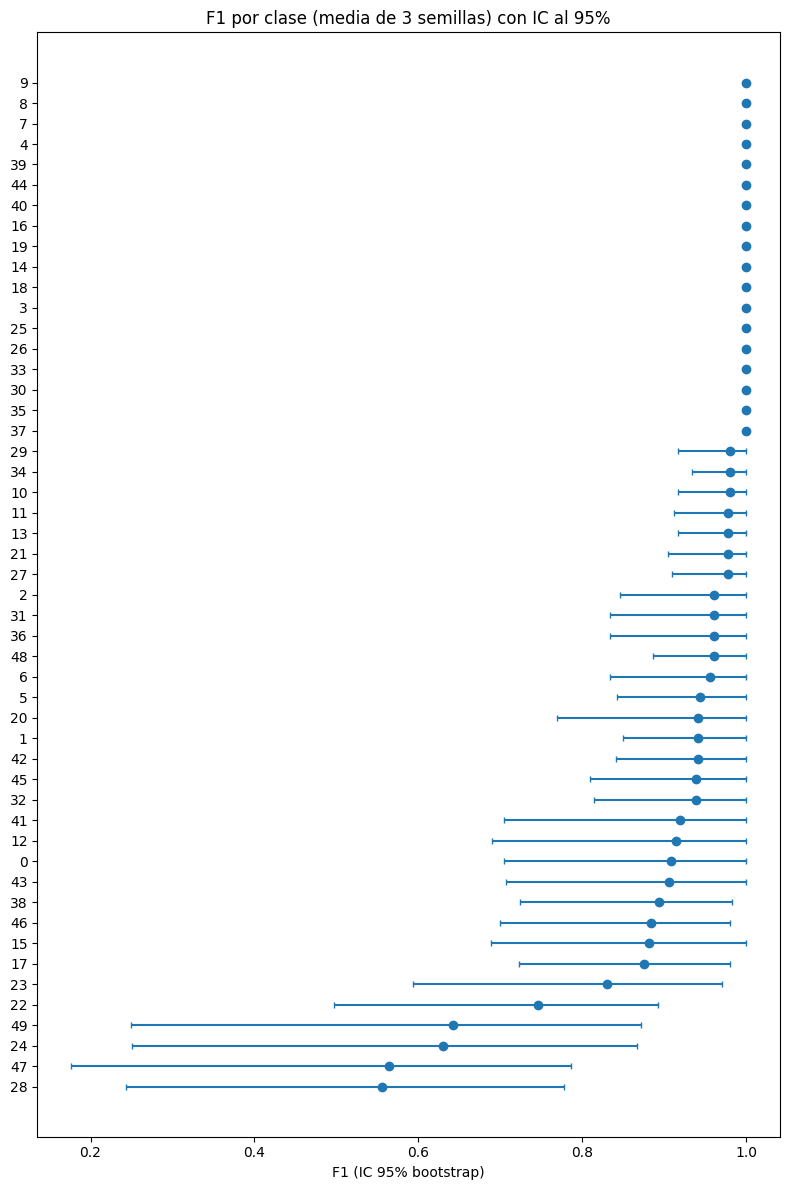

In [34]:
# IC 95% del F1 por clase
lo_c, hi_c = np.percentile(boot_f1_cls, [2.5, 97.5], axis=0)
f1_c = np.mean([precision_recall_fscore_support(y_true, p, labels=labels_present, zero_division=0)[2] for p in preds_ft], axis=0)
df_cls_ci = pd.DataFrame({"clase": CLASS_NAMES, "F1": f1_c, "IC95% inf": lo_c, "IC95% sup": hi_c}).sort_values("F1")
display(df_cls_ci.round(3).head(10))

order = df_cls_ci.reset_index(drop=True)
plt.figure(figsize=(8, 12))
plt.errorbar(order["F1"], range(len(order)),
             xerr=[order["F1"] - order["IC95% inf"], order["IC95% sup"] - order["F1"]], fmt="o", capsize=2)
plt.yticks(range(len(order)), order["clase"]); plt.xlabel("F1 (IC 95% bootstrap)")
plt.title("F1 por clase (media de 3 semillas) con IC al 95%"); plt.tight_layout(); plt.show()

### 6.3 Comparación de configuraciones

Se comparan tres configuraciones sobre el mismo conjunto de test:

1. AST preentrenado sin ajustar, usado como extractor de características con una regresión logística encima (linear probe).
2. AST con fine-tuning de 2 épocas (el de la sección 4, con 3 semillas).
3. AST con fine-tuning de 2 épocas y SpecAugment [8], con las mismas semillas e hiperparámetros.

Entre la primera y la segunda se ve cuánto se gana al ajustar todo el modelo; entre la segunda y la tercera, el efecto del aumento de datos. El linear probe es determinista, así que tiene un único valor. Las tres configuraciones se evalúan con los mismos remuestreos del bootstrap, lo que permite calcular también el IC de la diferencia entre ellas. Si ese intervalo contiene el 0, no hay evidencia de que una sea mejor que la otra.

In [35]:
# linear probe: regresión logística sobre los embeddings del AST sin ajustar
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

train_eval_loader = DataLoader(train_ds, batch_size=BATCH_SIZE * 2, shuffle=False)
base_backbone = ASTModel.from_pretrained(MODEL_CKPT).to(DEVICE)
emb_train = extract_embeddings(base_backbone, train_eval_loader)
del base_backbone
y_train = np.array(train_ds.labels)

# el valor de C se elige con validación cruzada dentro de train, sin usar el test
probe = make_pipeline(StandardScaler(),
                      LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10], cv=5, max_iter=2000, n_jobs=-1))
probe.fit(emb_train, y_train)
y_pred_probe = probe.predict(emb_before)   # emb_before: embeddings de test del AST sin ajustar (sección 6.1)
print("Linear probe -> accuracy en test: %.4f" % accuracy_score(y_true, y_pred_probe))

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 971.12it/s]
[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.layernorm.bias   | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Linear probe -> accuracy en test: 0.9500


In [36]:
# tabla: media ± desviación entre semillas [IC 95 % bootstrap de la media entre semillas]
CFG_LP = "AST sin ajustar + reg. logística"
preds_cfg = {CFG_LP: [y_pred_probe],
             CFG_FT: [runs[CFG_FT][s] for s in SEEDS],
             CFG_SA: [runs[CFG_SA][s] for s in SEEDS]}
idx_all = np.random.default_rng(SEED).integers(0, n, (B, n))   # mismos remuestreos para todas las configuraciones

per_seed = {k: np.array([core_metrics(y_true, p) for p in ps]) for k, ps in preds_cfg.items()}   # (semillas, 4)
points = {k: v.mean(0) for k, v in per_seed.items()}
stds = {k: (v.std(0, ddof=1) if len(v) > 1 else np.full(4, np.nan)) for k, v in per_seed.items()}
boots = {k: np.array([np.mean([core_metrics(y_true[ix], p[ix]) for p in ps], axis=0) for ix in idx_all])
         for k, ps in preds_cfg.items()}

rows = []
for k in preds_cfg:
    row = {"Configuración": k}
    for j, nm in enumerate(NAMES):
        lo, hi = np.percentile(boots[k][:, j], [2.5, 97.5])
        sd = f" ± {stds[k][j]:.3f}" if len(preds_cfg[k]) > 1 else ""
        row[nm] = f"{points[k][j]:.3f}{sd} [{lo:.3f}, {hi:.3f}]"
    rows.append(row)
tabla = pd.DataFrame(rows).set_index("Configuración")
display(tabla)
tabla.to_csv("tabla_comparacion.csv")


,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Configuración,,,,
AST sin ajustar + reg. logística,"0.950 [0.927, 0.970]","0.953 [0.931, 0.972]","0.950 [0.928, 0.970]","0.949 [0.921, 0.968]"
AST ajustado,"0.933 ± 0.012 [0.913, 0.952]","0.941 ± 0.013 [0.918, 0.955]","0.933 ± 0.012 [0.917, 0.949]","0.929 ± 0.013 [0.905, 0.943]"
AST ajustado + SpecAugment,"0.943 ± 0.013 [0.923, 0.961]","0.946 ± 0.014 [0.927, 0.964]","0.943 ± 0.013 [0.925, 0.959]","0.941 ± 0.014 [0.918, 0.956]"


,Comparación,Métrica,Diferencia,IC95% inf,IC95% sup,¿El IC contiene 0?
0,AST ajustado - AST sin ajustar + reg. logística,Accuracy,-0.017,-0.034,0.000,sí
1,AST ajustado - AST sin ajustar + reg. logística,F1 (macro),-0.020,-0.041,-0.003,no
2,AST ajustado + SpecAugment - AST ajustado,Accuracy,0.010,-0.002,0.022,sí
3,AST ajustado + SpecAugment - AST ajustado,F1 (macro),0.012,-0.000,0.027,sí


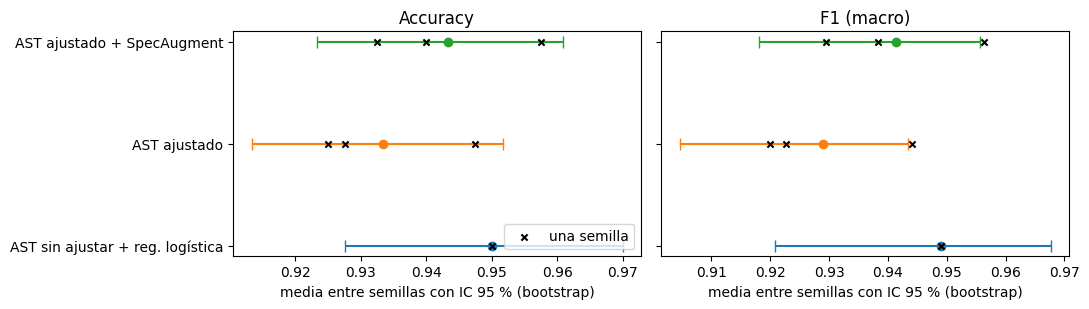

In [37]:
# diferencias entre configuraciones (bootstrap pareado sobre la media entre semillas)
pares = [(CFG_FT, CFG_LP), (CFG_SA, CFG_FT)]
rows = []
for a, c_ in pares:
    for j in (0, 3):
        d = boots[a][:, j] - boots[c_][:, j]
        lo, hi = np.percentile(d, [2.5, 97.5])
        rows.append({"Comparación": f"{a} - {c_}", "Métrica": NAMES[j],
                     "Diferencia": points[a][j] - points[c_][j], "IC95% inf": lo, "IC95% sup": hi,
                     "¿El IC contiene 0?": "sí" if lo <= 0 <= hi else "no"})
display(pd.DataFrame(rows).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, j in zip(axes, (0, 3)):
    for i, k in enumerate(preds_cfg):
        lo, hi = np.percentile(boots[k][:, j], [2.5, 97.5])
        ax.errorbar(points[k][j], i, xerr=[[points[k][j] - lo], [hi - points[k][j]]], fmt="o", capsize=4)
        ax.scatter(per_seed[k][:, j], np.full(len(per_seed[k]), i), marker="x", color="k", s=20, zorder=3,
                   label="una semilla" if (i == 1 and j == 0) else None)
    ax.set_yticks(range(len(preds_cfg))); ax.set_yticklabels(list(preds_cfg))
    ax.set_title(NAMES[j]); ax.set_xlabel("media entre semillas con IC 95 % (bootstrap)")
axes[0].legend(loc="lower right")
plt.tight_layout(); plt.show()


### 6.4 Análisis de errores por clase

Esta figura también suma las predicciones de las tres semillas. En (a) está la matriz de confusión por macro-categoría de ESC-50, normalizada por fila, y en (b) los diez pares de clases más confundidos, medidos como número medio de errores por semilla.

In [38]:
# Formato de figura

FIG_RC = {"font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 6,
          "ytick.labelsize": 6, "legend.fontsize": 6, "figure.dpi": 150}
DUR = VALID_FRAMES * 0.01                       # segundos con señal (~5 s)
MACRO_SHORT = ["Animales", "Naturaleza\ny agua", "Humanos\n(no habla)", "Doméstico", "Urbano"]
nm = lambda i: CLASS_NAMES[i].replace("_", " ")

def save_fig(fig, name):
    """Guarda la figura en PDF y PNG para el informe."""
    fig.savefig(f"{name}.pdf", bbox_inches="tight"); fig.savefig(f"{name}.png", dpi=300, bbox_inches="tight")

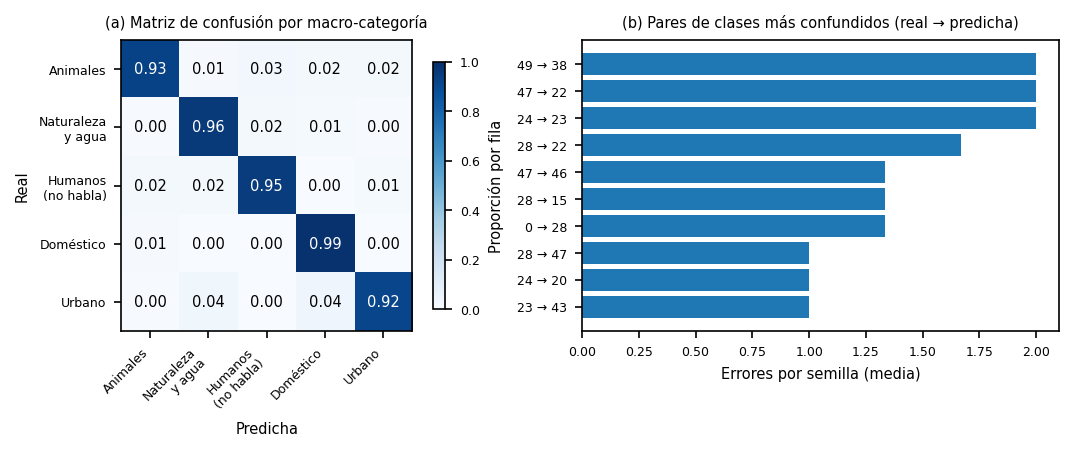

In [39]:
# matriz de confusión por macro-categoría y pares de clases más confundidos
with plt.rc_context(FIG_RC):
    # predicciones de las 3 semillas: errores medios por semilla
    cm_m = sum(confusion_matrix(y_true // 10, p // 10, labels=range(5)) for p in preds_ft)
    cm_n = cm_m / cm_m.sum(1, keepdims=True).clip(min=1)
    off_ = cm_seeds.mean(0); np.fill_diagonal(off_, 0)
    top10 = sorted([(off_[i, j], i, j) for i in range(NUM_LABELS) for j in range(NUM_LABELS) if off_[i, j] > 0],
                   reverse=True)[:10]

    fig, axes = plt.subplots(1, 2, figsize=(7.16, 2.9), constrained_layout=True, gridspec_kw={"width_ratios": [1, 1.15]})
    ax = axes[0]
    im = ax.imshow(cm_n, cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{cm_n[i, j]:.2f}", ha="center", va="center", color="white" if cm_n[i, j] > .5 else "black")
    ax.set_xticks(range(5)); ax.set_xticklabels(MACRO_SHORT, rotation=45, ha="right")
    ax.set_yticks(range(5)); ax.set_yticklabels(MACRO_SHORT)
    ax.set_xlabel("Predicha"); ax.set_ylabel("Real"); ax.set_title("(a) Matriz de confusión por macro-categoría")
    fig.colorbar(im, ax=ax, label="Proporción por fila", shrink=.85)

    ax = axes[1]
    labs = [f"{nm(i)} → {nm(j)}" for _, i, j in top10]
    ax.barh(range(len(top10)), [c for c, _, _ in top10], color="tab:blue")
    ax.set_yticks(range(len(top10))); ax.set_yticklabels(labs); ax.invert_yaxis()
    ax.set_xlabel("Errores por semilla (media)"); ax.set_title("(b) Pares de clases más confundidos (real → predicha)")
    save_fig(fig, "fig_confusion"); plt.show()

## 7. Resultados cualitativos

Los resultados cualitativos se muestran con un solo modelo, el de la semilla 42, porque un error concreto, su confianza o un mapa de atención solo tienen sentido para un modelo en particular. Se revisan los errores en los que el modelo estaba más seguro y se comparan sus espectrogramas con los de la clase real; después vienen la proyección t-SNE de los embeddings y los mapas de atención sobre el espectrograma.

### 7.1 Análisis de errores

Aquí se mira en qué se equivoca el modelo y por qué. Primero se revisan las probabilidades de cada predicción, luego los errores con mayor confianza, después los espectrogramas de los pares de clases que más se confunden y, por último, si las clases que se confunden son también las que tienen espectros parecidos.

In [40]:
# predicciones del modelo de la semilla 42
y_true, y_pred = predict(test_loader)
print("Coincidencia con las predicciones guardadas en el entrenamiento: %.3f" % (y_pred == runs[CFG_FT][SEED]).mean())
print(f"Modelo de la semilla {SEED}: accuracy en test {accuracy_score(y_true, y_pred):.4f}")

logits = predict_logits(test_loader, model)
probs  = torch.softmax(logits, -1).numpy()
assert (probs.argmax(1) == y_pred).all()

df_pred = pd.DataFrame({
    "idx": np.arange(len(y_true)),
    "real": [CLASS_NAMES[i] for i in y_true],
    "predicha": [CLASS_NAMES[i] for i in y_pred],
    "conf_predicha": probs.max(1),
    "prob_clase_real": probs[np.arange(len(y_true)), y_true],
    "ok": y_true == y_pred})

print("Confianza media (aciertos): %.3f | (errores): %.3f" %
      (df_pred.loc[df_pred.ok, "conf_predicha"].mean(), df_pred.loc[~df_pred.ok, "conf_predicha"].mean()))
print("\nErrores en los que el modelo estaba MÁS seguro:")
display(df_pred[~df_pred.ok].sort_values("conf_predicha", ascending=False).head(10).round(3))

Coincidencia con las predicciones guardadas en el entrenamiento: 1.000
Modelo de la semilla 42: accuracy en test 0.9275
Confianza media (aciertos): 0.972 | (errores): 0.730

Errores en los que el modelo estaba MÁS seguro:


,idx,real,predicha,conf_predicha,prob_clase_real,ok
307,307,24,31,0.995,0.000,False
240,240,49,38,0.993,0.002,False
152,152,24,20,0.992,0.002,False
54,54,24,23,0.984,0.010,False
272,272,47,45,0.983,0.005,False
132,132,17,32,0.966,0.026,False
159,159,24,23,0.961,0.030,False
165,165,47,22,0.940,0.021,False
380,380,22,28,0.915,0.068,False
222,222,47,22,0.890,0.068,False


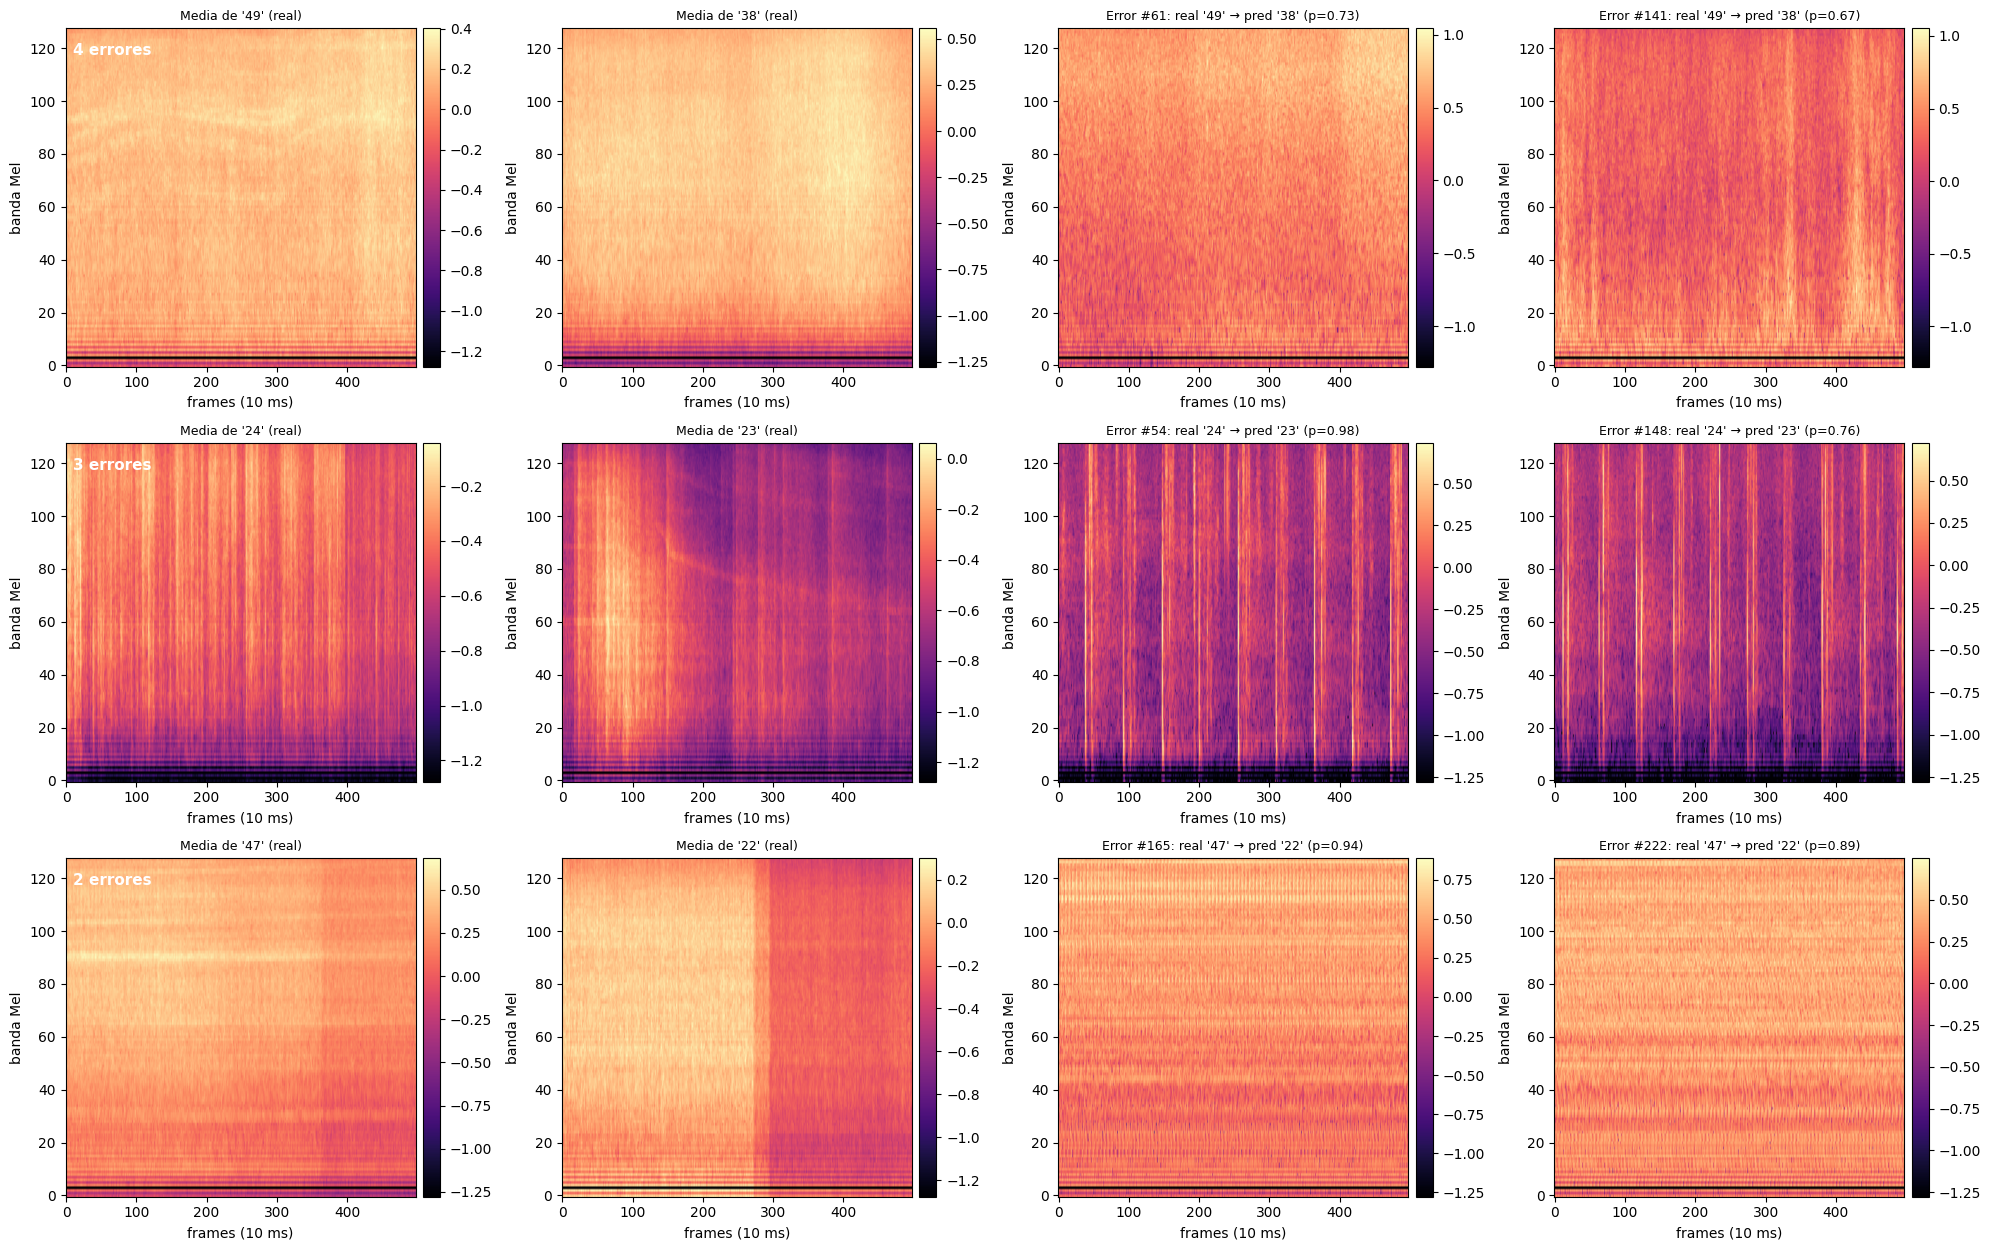

In [41]:
# pares más confundidos con sus espectrogramas
y_true_t = np.array(y_true)

off = confusion_matrix(y_true, y_pred, labels=labels_present); np.fill_diagonal(off, 0)
pair_list = sorted([(off[i, j], i, j) for i in range(NUM_LABELS) for j in range(NUM_LABELS) if off[i, j] > 0],
                   reverse=True)[:3]

fig, axes = plt.subplots(len(pair_list), 4, figsize=(20, 4.2 * len(pair_list)))
axes = np.atleast_2d(axes)
for r, (cnt, a, bcls) in enumerate(pair_list):
    mean_a = specs_test[y_true_t == a].mean(0)[:VALID_FRAMES]
    mean_b = specs_test[y_true_t == bcls].mean(0)[:VALID_FRAMES]
    err_idx = np.where((y_true == a) & (y_pred == bcls))[0][:2]
    panels = [(mean_a, f"Media de '{CLASS_NAMES[a]}' (real)"), (mean_b, f"Media de '{CLASS_NAMES[bcls]}' (real)")]
    for k in err_idx:
        panels.append((specs_test[k][:VALID_FRAMES], f"Error #{k}: real '{CLASS_NAMES[a]}' → pred '{CLASS_NAMES[bcls]}' (p={probs[k, bcls]:.2f})"))
    for c in range(4):
        ax = axes[r, c]
        if c < len(panels):
            im = ax.imshow(panels[c][0].T, origin="lower", aspect="auto", cmap="magma"); ax.set_title(panels[c][1], fontsize=9)
            fig.colorbar(im, ax=ax, fraction=.046, pad=.02)
            ax.set_xlabel("frames (10 ms)"); ax.set_ylabel("banda Mel")
        else:
            ax.axis("off")
    axes[r, 0].annotate(f"{cnt} errores", (0.02, 0.92), xycoords="axes fraction", color="w", fontsize=11, weight="bold")
plt.tight_layout(); plt.show()

In [42]:
# para escuchar el error más seguro
try:
    from IPython.display import Audio, display
    k = int(df_pred[~df_pred.ok].sort_values("conf_predicha", ascending=False).iloc[0]["idx"])
    print(f"Audio #{k}: real = {CLASS_NAMES[y_true[k]]} | predicha = {CLASS_NAMES[y_pred[k]]}")
    w_k, sr_k = get_audio(val_dataset[k]["audio"]); display(Audio(w_k.numpy(), rate=sr_k))
except Exception as e:
    print("No se pudo reproducir el audio:", e)

Audio #307: real = 24 | predicha = 31


Correlación de Spearman (similitud espectral vs. confusiones): rho = 0.121 (p = 2.26e-05)


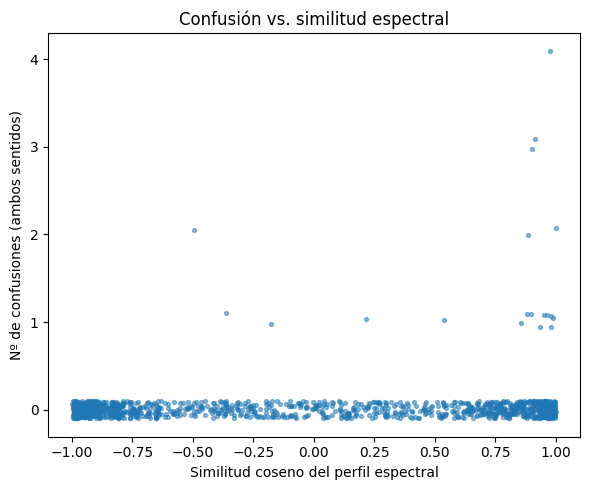

In [43]:
# ¿se confunden más las clases que suenan parecido?
# perfil espectral medio por clase (promedio en el tiempo) y similitud coseno
from scipy.stats import spearmanr
profiles = np.stack([specs_test[y_true_t == c][:, :VALID_FRAMES].mean((0, 1)).numpy() if (y_true_t == c).any()
                     else np.zeros(N_MELS) for c in range(NUM_LABELS)])
prof_c = profiles - profiles.mean(0)  # centrado
sim = (prof_c @ prof_c.T) / (np.linalg.norm(prof_c, axis=1)[:, None] * np.linalg.norm(prof_c, axis=1)[None] + 1e-9)

iu = np.triu_indices(NUM_LABELS, k=1)
conf_sym = (off + off.T)[iu]  # errores en ambos sentidos
rho, pval = spearmanr(sim[iu], conf_sym)
print(f"Correlación de Spearman (similitud espectral vs. confusiones): rho = {rho:.3f} (p = {pval:.3g})")

plt.figure(figsize=(6, 5))
plt.scatter(sim[iu], conf_sym + np.random.RandomState(0).uniform(-.1, .1, len(conf_sym)), s=8, alpha=.5)
plt.xlabel("Similitud coseno del perfil espectral"); plt.ylabel("Nº de confusiones (ambos sentidos)")
plt.title("Confusión vs. similitud espectral"); plt.tight_layout(); plt.show()

#### Aciertos y errores

Espectrogramas log-Mel normalizados de dos aciertos (a, b) y dos errores (c, d) del test, con la clase real y la predicha.

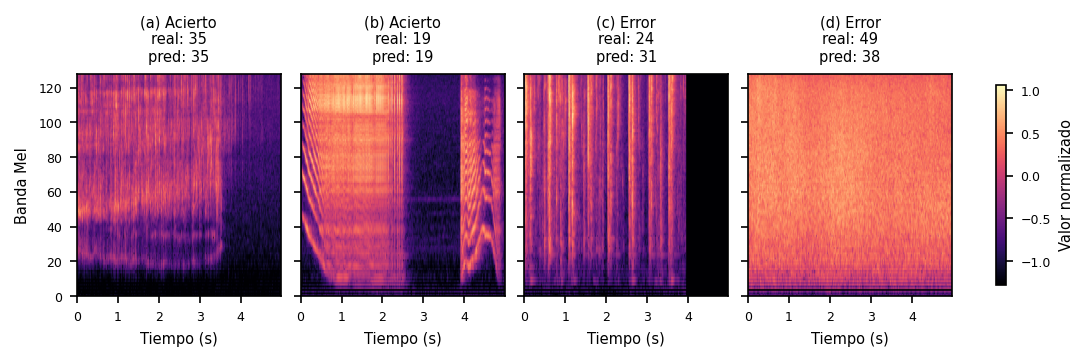

In [44]:
# Espectrogramas de aciertos y errores (real frente a predicho)
def pick(df, n_ex, ok):
    """Índices de test con la mayor confianza, con clases reales distintas."""
    d = df[df.ok == ok].sort_values("conf_predicha", ascending=False).drop_duplicates("real")
    return d.idx.values[:n_ex].astype(int)

ex_ok, ex_bad = pick(df_pred, 2, True), pick(df_pred, 2, False)   # también se usan en la figura de mapas de atención

with plt.rc_context(FIG_RC):
    sel = list(ex_ok) + list(ex_bad)
    vals = [specs_test[k][:VALID_FRAMES].numpy() for k in sel]
    vmin, vmax = min(v.min() for v in vals), max(v.max() for v in vals)

    fig, axes = plt.subplots(1, 4, figsize=(7.16, 2.3), sharey=True, constrained_layout=True)
    for ax, k, v in zip(axes, sel, vals):
        im = ax.imshow(v.T, origin="lower", aspect="auto", cmap="magma", extent=[0, DUR, 0, N_MELS], vmin=vmin, vmax=vmax)
        tipo = "Acierto" if y_true[k] == y_pred[k] else "Error"
        ax.set_title(f"({'abcd'[sel.index(k)]}) {tipo}\nreal: {nm(y_true[k])}\npred: {nm(y_pred[k])}")
        ax.set_xlabel("Tiempo (s)")
    axes[0].set_ylabel("Banda Mel")
    fig.colorbar(im, ax=axes, label="Valor normalizado", shrink=.9)
    save_fig(fig, "fig_aciertos_errores"); plt.show()

### 7.2 t-SNE y mapas de atención

Para el t-SNE [10] cada audio se representa con su embedding del AST de la sección 6.1 (el `pooler_output`, de 768 dimensiones) y se proyecta a 2D. Se hace con el modelo preentrenado y con el ajustado, y la separación entre clases se mide con el silhouette score.

Los mapas de atención se calculan con attention rollout [11]: se promedian las cabezas, se suma la conexión residual, se normaliza y se multiplican las matrices de todas las capas. La fila del token CLS indica qué parches del espectrograma pesan más en la decisión. Hay que tomarlo como una pista visual, no como prueba de lo que el modelo usa realmente.

Silhouette (coseno, 50 clases): antes = 0.365 | después = 0.576


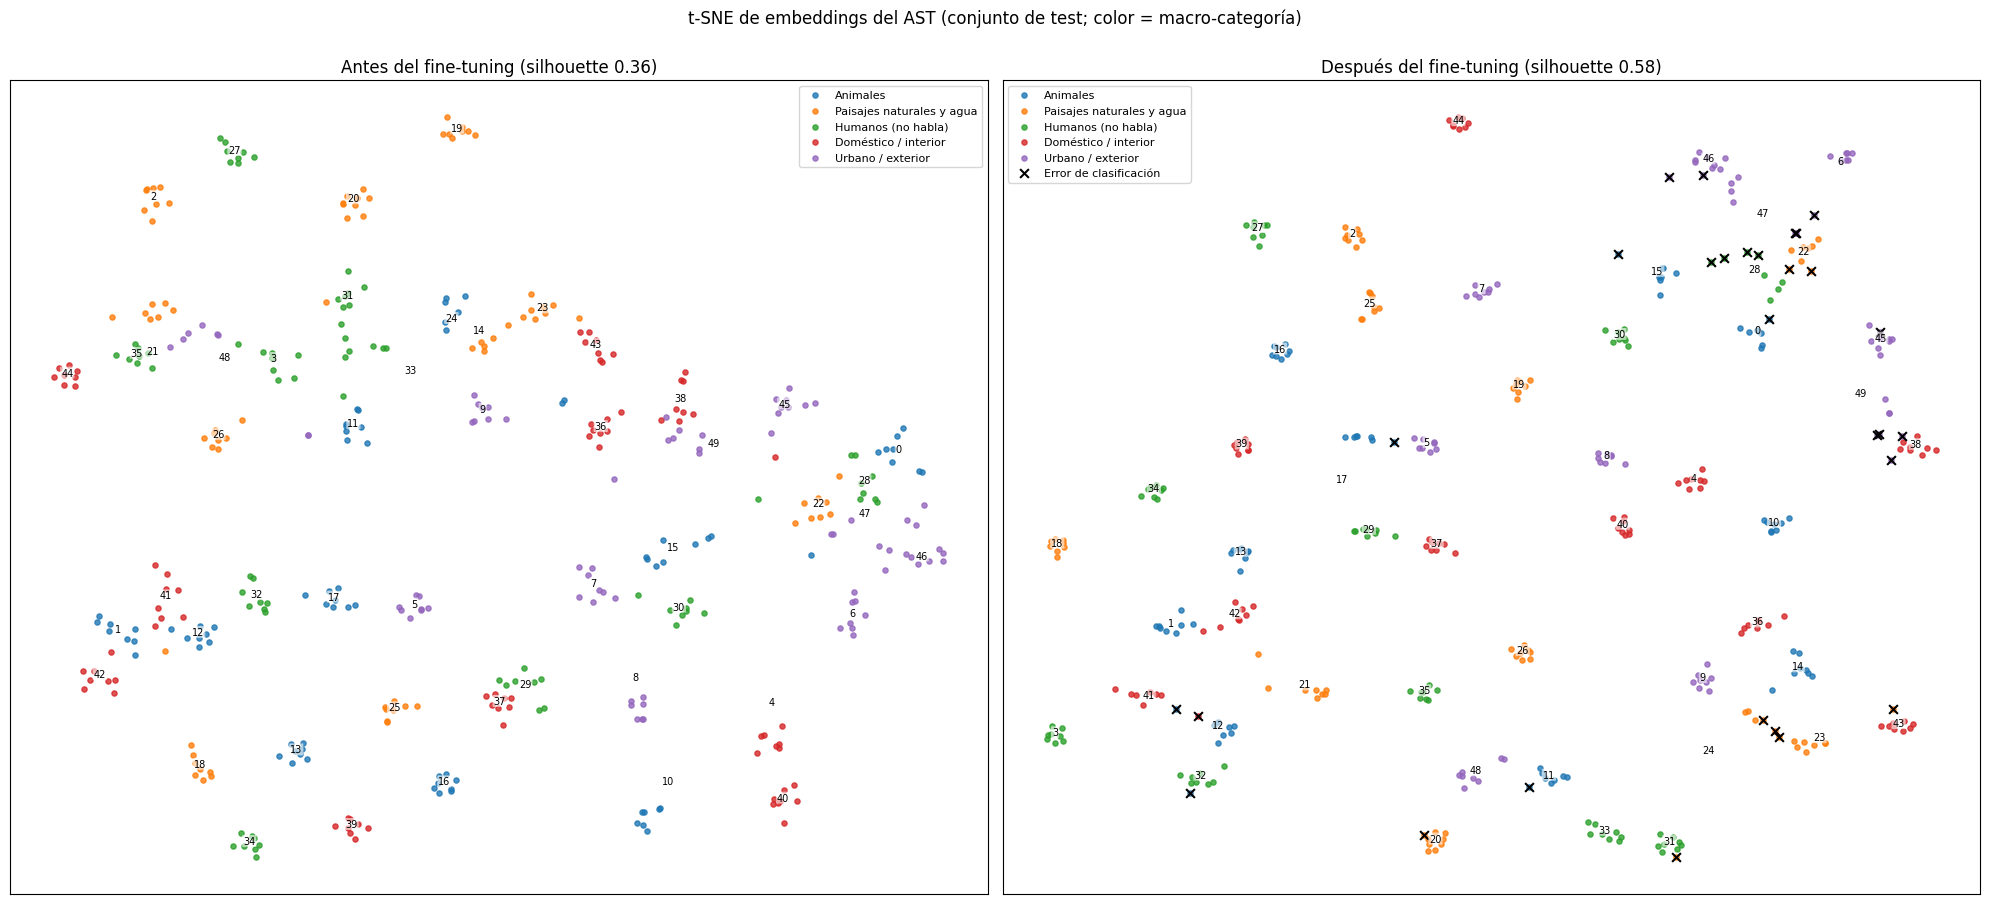

In [45]:
def run_tsne(emb, perplexity=30):
    return TSNE(n_components=2, perplexity=perplexity, init="pca", metric="cosine",
                random_state=SEED).fit_transform(emb)

xy_before, xy_after = run_tsne(emb_before), run_tsne(emb_after)
sil_before = silhouette_score(emb_before, y_true, metric="cosine")
sil_after  = silhouette_score(emb_after,  y_true, metric="cosine")
print(f"Silhouette (coseno, 50 clases): antes = {sil_before:.3f} | después = {sil_after:.3f}")

macro_colors = plt.cm.tab10(np.arange(5))
fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, xy, title in zip(axes, [xy_before, xy_after], [f"Antes del fine-tuning (silhouette {sil_before:.2f})",
                                                       f"Después del fine-tuning (silhouette {sil_after:.2f})"]):
    for m in range(5):
        sel = (y_true // 10) == m
        ax.scatter(xy[sel, 0], xy[sel, 1], s=14, color=macro_colors[m], label=MACRO[m], alpha=.8)
    for c in range(NUM_LABELS):  # nombre de la clase en su centroide
        sel = y_true == c
        if sel.any(): ax.text(*xy[sel].mean(0), CLASS_NAMES[c], fontsize=7, ha="center",
                              bbox=dict(boxstyle="round,pad=.1", fc="w", alpha=.6, lw=0))
    if ax is axes[1]:  # marco los errores
        wrong = y_true != y_pred
        ax.scatter(xy[wrong, 0], xy[wrong, 1], marker="x", color="k", s=40, label="Error de clasificación")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.legend(fontsize=8, loc="best")
plt.suptitle("t-SNE de embeddings del AST (conjunto de test; color = macro-categoría)", y=1.0)
plt.tight_layout(); plt.show()

In [46]:
# con atención 'eager' porque las otras implementaciones no devuelven los pesos
try:
    model_attn = ASTForAudioClassification.from_pretrained(FT_DIR, attn_implementation="eager").to(DEVICE).eval()
except Exception:
    model_attn = ASTForAudioClassification.from_pretrained(FT_DIR).to(DEVICE).eval()

cfg = model_attn.config
F_OUT = (cfg.num_mel_bins - cfg.patch_size) // cfg.frequency_stride + 1  # 12
T_OUT = (cfg.max_length   - cfg.patch_size) // cfg.time_stride      + 1  # 101
print("Parches (frecuencia x tiempo):", F_OUT, "x", T_OUT)

@torch.no_grad()
def attention_rollout(x):
    """Mapa de atención (F_OUT, T_OUT) del CLS sobre los parches de un espectrograma."""
    out = model_attn(input_values=x.unsqueeze(0).to(DEVICE), output_attentions=True)
    assert out.attentions is not None and out.attentions[0] is not None, "El modelo no devolvió atenciones"
    Tn = out.attentions[0].shape[-1]
    I = torch.eye(Tn, device=DEVICE); roll = I.clone()
    for a in out.attentions:
        a = a[0].float().mean(0) + I  # promedio de cabezas más la conexión residual
        a = a / a.sum(-1, keepdim=True)
        roll = a @ roll
    m = roll[:2, 2:].mean(0).reshape(F_OUT, T_OUT)  # tokens 0 y 1: CLS y destilación
    m = (m - m.min()) / (m.max() - m.min() + 1e-9)
    return m.cpu()

Loading weights: 100%|██████████| 203/203 [00:00<00:00, 820.82it/s]


Parches (frecuencia x tiempo): 12 x 101


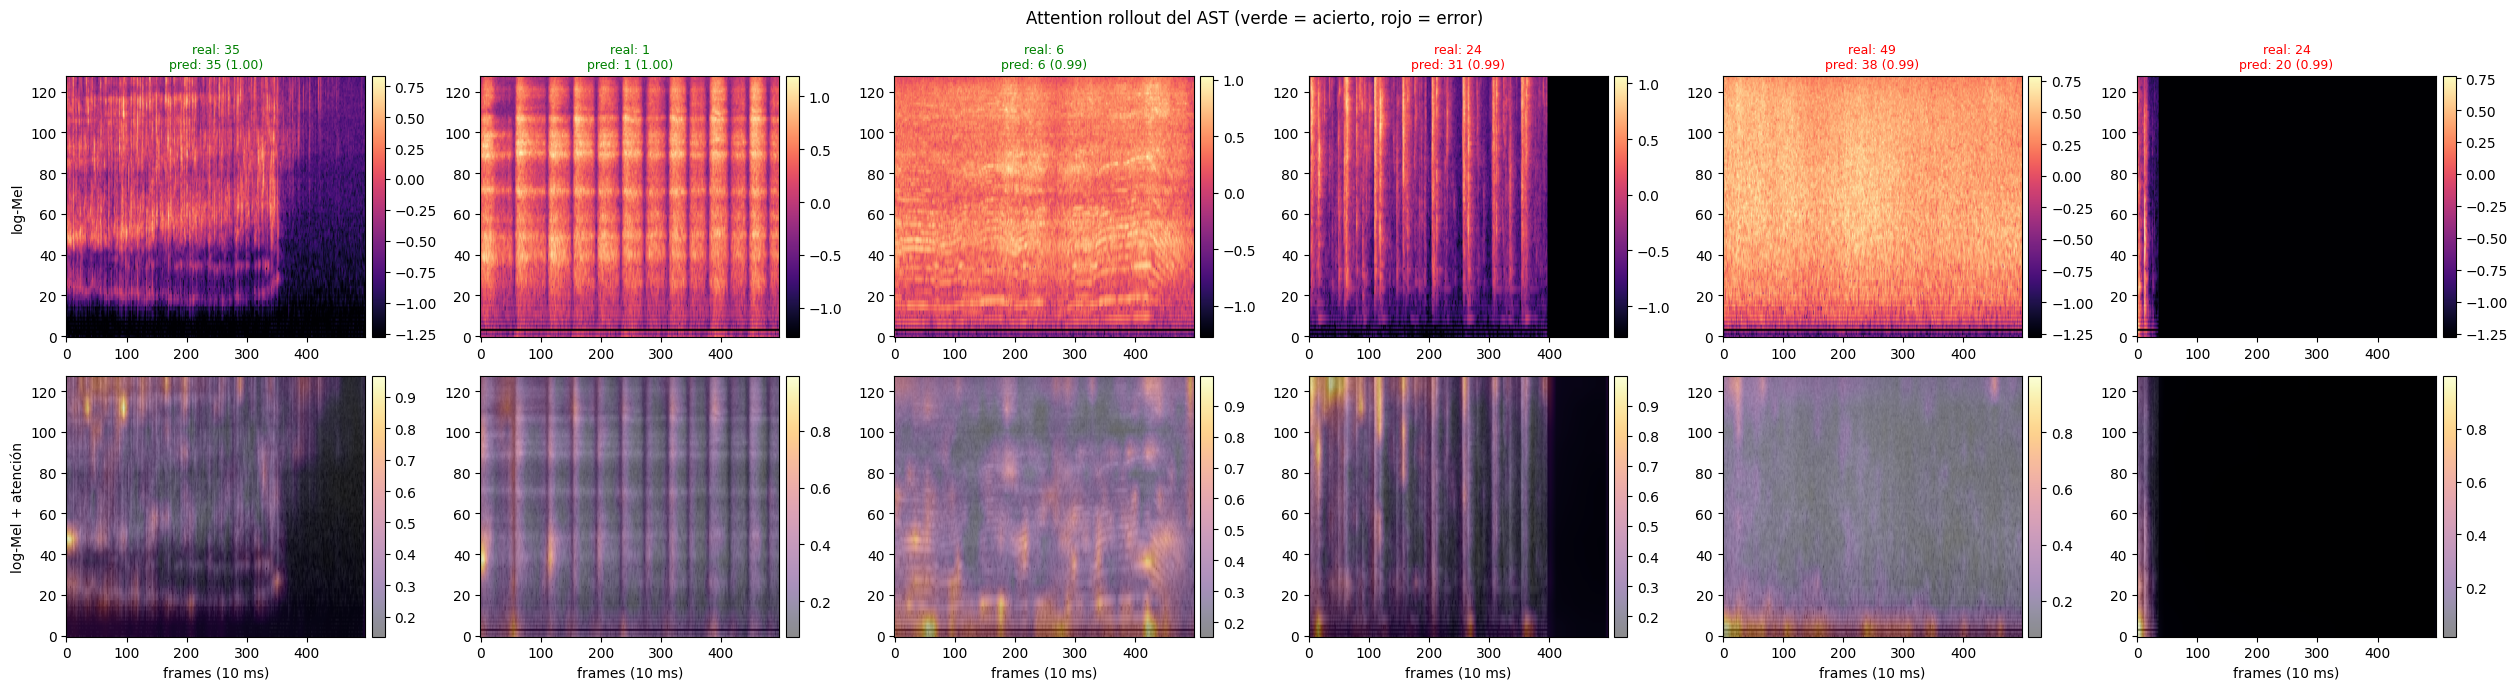

In [47]:
# 3 aciertos seguros y 3 errores
ok_idx  = df_pred[df_pred.ok].sort_values("conf_predicha", ascending=False).idx.values
bad_idx = df_pred[~df_pred.ok].sort_values("conf_predicha", ascending=False).idx.values
chosen = list(ok_idx[:: max(1, len(ok_idx) // 3)][:3]) + list(bad_idx[:3])

fig, axes = plt.subplots(2, len(chosen), figsize=(4.2 * len(chosen), 7))
for j, k in enumerate(chosen):
    k = int(k); x = specs_test[k]
    att = attention_rollout(x)
    att_up = torch.nn.functional.interpolate(att[None, None], size=(N_MELS, cfg.max_length),
                                             mode="bilinear", align_corners=False)[0, 0]
    spec_img = x.T[:, :VALID_FRAMES].numpy()
    title = f"real: {CLASS_NAMES[y_true[k]]}\npred: {CLASS_NAMES[y_pred[k]]} ({probs[k].max():.2f})"
    im0 = axes[0, j].imshow(spec_img, origin="lower", aspect="auto", cmap="magma"); axes[0, j].set_title(title, fontsize=9,
        color="green" if y_true[k] == y_pred[k] else "red")
    axes[1, j].imshow(spec_img, origin="lower", aspect="auto", cmap="gray")
    im1 = axes[1, j].imshow(att_up[:, :VALID_FRAMES].numpy(), origin="lower", aspect="auto", cmap="inferno", alpha=.45)
    fig.colorbar(im0, ax=axes[0, j], fraction=.046, pad=.02); fig.colorbar(im1, ax=axes[1, j], fraction=.046, pad=.02)
    axes[1, j].set_xlabel("frames (10 ms)")
axes[0, 0].set_ylabel("log-Mel"); axes[1, 0].set_ylabel("log-Mel + atención")
plt.suptitle("Attention rollout del AST (verde = acierto, rojo = error)"); plt.tight_layout(); plt.show()

#### Mapas de atención

Mapas de atención (attention rollout) del token CLS sobre el espectrograma para un acierto (a) y dos errores (b, c). Arriba, el espectrograma; abajo, la atención superpuesta.

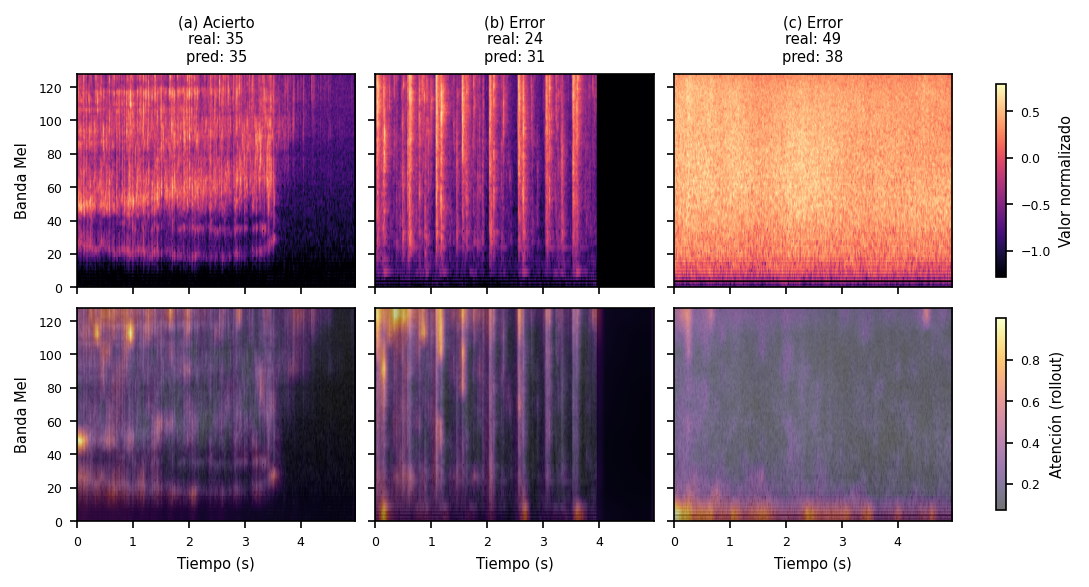

In [48]:
# Figura: mapas de atención (attention rollout) de un acierto y dos errores
with plt.rc_context(FIG_RC):
    ex_att = [int(ex_ok[0]), int(ex_bad[0]), int(ex_bad[1])]
    fig, axes = plt.subplots(2, 3, figsize=(7.16, 3.8), sharex=True, sharey=True, constrained_layout=True)
    for j, k in enumerate(ex_att):
        x = specs_test[k]
        att = attention_rollout(x)
        att_up = torch.nn.functional.interpolate(att[None, None], size=(N_MELS, cfg.max_length),
                                                 mode="bilinear", align_corners=False)[0, 0]
        spec = x[:VALID_FRAMES].T.numpy()
        im0 = axes[0, j].imshow(spec, origin="lower", aspect="auto", cmap="magma", extent=[0, DUR, 0, N_MELS])
        axes[1, j].imshow(spec, origin="lower", aspect="auto", cmap="gray", extent=[0, DUR, 0, N_MELS])
        im1 = axes[1, j].imshow(att_up[:, :VALID_FRAMES].numpy(), origin="lower", aspect="auto", cmap="inferno",
                                alpha=.55, extent=[0, DUR, 0, N_MELS])
        tipo = "Acierto" if y_true[k] == y_pred[k] else "Error"
        axes[0, j].set_title(f"({'abc'[j]}) {tipo}\nreal: {nm(y_true[k])}\npred: {nm(y_pred[k])}")
        axes[1, j].set_xlabel("Tiempo (s)")
    axes[0, 0].set_ylabel("Banda Mel"); axes[1, 0].set_ylabel("Banda Mel")
    fig.colorbar(im0, ax=axes[0, :], label="Valor normalizado", shrink=.9)
    fig.colorbar(im1, ax=axes[1, :], label="Atención (rollout)", shrink=.9)
    save_fig(fig, "fig_atencion"); plt.show()

## Referencias

[1] Y. Gong, Y.-A. Chung, and J. Glass, "AST: Audio Spectrogram Transformer," in *Proc. Interspeech 2021*, Brno, Czechia, 2021, pp. 571–575, doi: 10.21437/Interspeech.2021-698.

[2] A. Vaswani et al., "Attention is all you need," in *Advances in Neural Information Processing Systems (NeurIPS)*, vol. 30, 2017.

[3] "MIT/ast-finetuned-audioset-10-10-0.4593," Hugging Face Hub. Accessed: Nov. 20, 2026. [Online]. Available: https://huggingface.co/MIT/ast-finetuned-audioset-10-10-0.4593

[4] K. J. Piczak, "ESC: Dataset for environmental sound classification," in *Proc. 23rd ACM Int. Conf. Multimedia (MM '15)*, Brisbane, Australia, 2015, pp. 1015–1018, doi: 10.1145/2733373.2806390.

[5] J. F. Gemmeke et al., "Audio Set: An ontology and human-labeled dataset for audio events," in *Proc. IEEE Int. Conf. Acoust., Speech, Signal Process. (ICASSP)*, New Orleans, LA, USA, 2017, pp. 776–780, doi: 10.1109/ICASSP.2017.7952261.

[6] A. Dosovitskiy et al., "An image is worth 16x16 words: Transformers for image recognition at scale," in *Proc. Int. Conf. Learn. Representations (ICLR)*, 2021.

[7] I. Loshchilov and F. Hutter, "Decoupled weight decay regularization," in *Proc. Int. Conf. Learn. Representations (ICLR)*, 2019.

[8] D. S. Park et al., "SpecAugment: A simple data augmentation method for automatic speech recognition," in *Proc. Interspeech 2019*, Graz, Austria, 2019, pp. 2613–2617, doi: 10.21437/Interspeech.2019-2680.

[9] B. Efron and R. J. Tibshirani, *An Introduction to the Bootstrap*. New York, NY, USA: Chapman & Hall, 1993.

[10] L. van der Maaten and G. Hinton, "Visualizing data using t-SNE," *J. Mach. Learn. Res.*, vol. 9, pp. 2579–2605, Nov. 2008.

[11] S. Abnar and W. Zuidema, "Quantifying attention flow in transformers," in *Proc. 58th Annu. Meeting Assoc. Comput. Linguistics (ACL)*, Online, 2020, pp. 4190–4197, doi: 10.18653/v1/2020.acl-main.385.